# Fish species in Catoctin Mountain Park (USA) — Exploratory Data Analysis

**Data:** USGS data release (Hitt, Snyder & Snook 2018). Summer 2015 backpack electrofishing of 100 m reaches in Owens Creek, Big Hunting Creek and Blue Blazes Creek (Maryland), plus physical habitat measured along transects and stream temperature loggers (2015–2016).

**Study motivation:** protecting cold-water streams and native brook trout (*Salvelinus fontinalis*, SAFO) under climate change.

**Research question (draft):** Which environmental variables best explain variation in fish community composition among stream reaches, after accounting for sampling effort?


## 0. Packages and helper function

In [35]:
# Run once, then comment out:
# install.packages(c("vegan", "pastecs", "psych", "gplots", "cluster"))
library(vegan)    # vegdist(), decostand(), mantel()
library(pastecs)  # stat.desc()
library(psych)    # describeBy()
library(gplots)   # heatmap.2()
library(cluster)  # daisy()

In [36]:
# Helper from the course notes: draws a matrix as a labelled colour grid
# (dark purple = low values, yellow = high values)
image.real <- function(mat, main = "") {
  mat <- as.matrix(mat)
  n_r <- nrow(mat); n_c <- ncol(mat)
  image(t(mat)[, n_r:1], axes = FALSE,
        col = hcl.colors(15, palette = "viridis"), main = main)
  axis(1, at = seq(0, 1, length = n_c), labels = colnames(mat), las = 2, cex.axis = 0.7)
  axis(2, at = seq(0, 1, length = n_r), labels = rev(rownames(mat)), las = 1, cex.axis = 0.5, gap.axis = -1)
  }


## 1. Load the data

The notebook must be in the same folder as the CSV files (the `Rapport` repo).
`na.strings` turns blank cells and the Excel error `#VALUE!` into `NA` straight away.

In [37]:
na_vals <- c("", "NA", "#VALUE!")
fish    <- read.csv("Catoctin_FishData.csv",     na.strings = na_vals)
habitat <- read.csv("Catoctin_FishHabitat.csv",  na.strings = na_vals)
sites   <- read.csv("Catoctin_FishSites.csv",    na.strings = na_vals)
temp    <- read.csv("Catoctin_Temperature.csv",  na.strings = na_vals)   # 21 MB, takes a few seconds
loggers <- read.csv("Catoctin_LoggerSites.csv",  na.strings = na_vals)

## 2. First look at the fish data

What the columns mean (from the metadata):
- **ReachID** – a 100 m stretch of stream that was fished (e.g. FOM01 = **F**ish, **O**wens, **M**ainstem, site 1). 64 reaches.
- **Effort** – seconds the electrofisher was switched on (143–2484 s).
- **Species** – 4-letter code (first 2 letters of genus + first 2 of species).
- **Count** – number of fish, for **non-trout** species (tallied).
- **Length / Weight** – mm / g, for **trout only** (SAFO, SATR), one row per measured fish, with no Count.

In [38]:
names(fish)
str(fish)
head(fish)
dim(fish)

[1] "Date"      "Time"      "Watershed" "ReachID"   "Effort"    "Species"  
[7] "Length"    "Weight"    "Count"

'data.frame':	1221 obs. of  9 variables:
 $ Date     : chr  "7/28/2015" "7/28/2015" "7/28/2015" "7/28/2015" ...
 $ Time     : chr  "10:00 AM" "10:00 AM" "10:00 AM" "10:00 AM" ...
 $ Watershed: chr  "Big Hunting" "Big Hunting" "Big Hunting" "Big Hunting" ...
 $ ReachID  : chr  "FBB01" "FBB01" "FBB01" "FBB01" ...
 $ Effort   : int  823 823 823 823 823 823 823 823 823 823 ...
 $ Species  : chr  "COCA" "ETFL" "RHAT" "RHCA" ...
 $ Length   : int  NA NA NA NA 234 66 71 66 65 66 ...
 $ Weight   : num  NA NA NA NA 123 ...
 $ Count    : int  9 4 90 1 NA NA NA NA NA NA ...


,Date,Time,Watershed,ReachID,Effort,Species,Length,Weight,Count
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<dbl>,<int>
1,7/28/2015,10:00 AM,Big Hunting,FBB01,823,COCA,NA,NA,9
2,7/28/2015,10:00 AM,Big Hunting,FBB01,823,ETFL,NA,NA,4
3,7/28/2015,10:00 AM,Big Hunting,FBB01,823,RHAT,NA,NA,90
4,7/28/2015,10:00 AM,Big Hunting,FBB01,823,RHCA,NA,NA,1
5,7/28/2015,10:00 AM,Big Hunting,FBB01,823,SATR,234,122.7,NA
6,7/28/2015,10:00 AM,Big Hunting,FBB01,823,SATR,66,3.1,NA


[1] 1221    9

## 3. Descriptive statistics

In [39]:
summary(fish)
stat.desc(fish[sapply(fish, is.numeric)])   # numeric columns only

        Date             Time          Watershed         ReachID    
 Length   :1221   Length   :1221   Length   :1221   Length   :1221  
 N.unique :  16   N.unique :  24   N.unique :   2   N.unique :  64  
 N.blank  :   0   N.blank  :   0   N.blank  :   0   N.blank  :   0  
 Min.nchar:   8   Min.nchar:   7   Min.nchar:   5   Min.nchar:   5  
 Max.nchar:   9   Max.nchar:   8   Max.nchar:  11   Max.nchar:   5  
                                                                    
                                                                    
     Effort          Species         Length           Weight      
 Min.   : 143   Length   :1221   Min.   : 43.00   Min.   :  0.70  
 1st Qu.:1244   N.unique :  13   1st Qu.: 63.00   1st Qu.:  2.45  
 Median :1558   N.blank  :   0   Median : 70.00   Median :  3.40  
 Mean   :1540   Min.nchar:   4   Mean   : 95.42   Mean   : 17.69  
 3rd Qu.:1800   Max.nchar:   4   3rd Qu.:133.00   3rd Qu.: 22.15  
 Max.   :2484                    Max.   :318.0

,Effort,Length,Weight,Count
,<dbl>,<dbl>,<dbl>,<dbl>
nbr.val,1.221000e+03,9.630000e+02,963.000000,256.000000
nbr.null,0.000000e+00,0.000000e+00,0.000000,0.000000
nbr.na,0.000000e+00,2.580000e+02,258.000000,965.000000
min,1.430000e+02,4.300000e+01,0.700000,1.000000
max,2.484000e+03,3.180000e+02,316.500000,423.000000
range,2.341000e+03,2.750000e+02,315.800000,422.000000
sum,1.880489e+06,9.189200e+04,17037.100000,14380.000000
median,1.558000e+03,7.000000e+01,3.400000,15.000000
mean,1.540122e+03,9.542264e+01,17.691693,56.171875


## 4. Site × species matrix (`spe`)

Rows = 64 reaches, columns = 13 species, cells = number of fish.

Important: trout rows have `Count = NA` because each trout was measured individually.
Each of those rows is **one fish**, so we set `n = 1` for them. Without this, brook trout (SAFO) and brown trout (SATR) would wrongly appear as 0.

In [40]:
fish$n <- ifelse(is.na(fish$Count), 1, fish$Count)

spe <- tapply(fish$n, list(fish$ReachID, fish$Species), sum)
spe[is.na(spe)] <- 0          # species not caught in a reach = 0
spe <- as.data.frame(spe)
dim(spe)                      # 64 reaches x 13 species
spe

[1] 64 13

,AMNA,CACO,CLFU,COCA,COGI,ETFL,LEMA,MISA,RHAT,RHCA,SAFO,SATR,SEAT
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FBB01,0,0,0,9,0,4,0,0,90,1,0,11,0
FBB02,0,0,0,8,0,0,0,0,113,0,0,1,0
FBB03,0,0,0,42,0,0,0,0,166,0,0,3,0
FBB04,0,0,0,34,0,0,0,0,193,0,0,9,0
FBB05,0,0,0,14,0,0,0,0,237,0,0,9,0
FBB06,0,0,0,25,0,0,0,0,189,0,0,1,0
FBB07,0,0,0,13,0,0,0,0,141,0,0,1,0
FBB08,0,0,0,0,0,0,0,0,182,0,0,0,0
FBB09,0,0,0,0,0,0,0,0,150,0,0,0,0


In [41]:
# Was each reach sampled only once? (all values should be 1)
table(tapply(fish$Date, fish$ReachID, function(d) length(unique(d))))

# Watershed and sampling effort per reach, in the same order as spe
ws  <- tapply(fish$Watershed, fish$ReachID, function(w) w[1])[rownames(spe)]
eff <- tapply(fish$Effort,    fish$ReachID, function(e) e[1])[rownames(spe)]
table(ws)


 1 
64 

ws
Big Hunting       Owens 
         18          46 

### Species codes

| Code | Common name | | Code | Common name |
|---|---|---|---|---|
| RHAT | Blacknose dace | | COGI | Potomac sculpin |
| COCA | Blue Ridge sculpin | | CACO | White sucker |
| SAFO | **Brook trout** (native, cold water) | | SATR | Brown trout (introduced) |
| RHCA | Longnose dace | | LEMA | Bluegill (rare) |
| SEAT | Creek chub | | MISA | Largemouth bass (rare) |
| CLFU | Rosyside dace | | AMNA | Yellow bullhead (rare) |
| ETFL | Fantail darter | | | |

## 5. Explore the community

In [42]:
sort(colSums(spe), decreasing = TRUE)   # total abundance per species
richness <- rowSums(spe > 0)            # number of species per reach
richness
round(100 * sort(colSums(spe), decreasing = TRUE) / sum(spe), 1)   # % of all fish

RHAT COCA SAFO RHCA SEAT CLFU ETFL SATR COGI CACO LEMA MISA AMNA 
9211 3973  903  318  306  267  230   62   34   32    6    2    1

FBB01 FBB02 FBB03 FBB04 FBB05 FBB06 FBB07 FBB08 FBB09 FBB10 FBB11 FBB12 FBM01 
    5     3     3     3     3     3     3     1     1     1     1     1     3 
FBM02 FBM03 FBM04 FBM05 FBM06 FOA01 FOA02 FOB01 FOB02 FOB03 FOB04 FOB05 FOB06 
    4     4     7     5     4     2     3     7     6     5     4     4     4 
FOB07 FOC01 FOC02 FOC03 FOC04 FOD01 FOD02 FOD03 FOD04 FOM01 FOM02 FOM03 FOM04 
    3     4     5     2     1     5     3     5     2     4     4     6     6 
FOM05 FOM06 FOM07 FOM08 FOM09 FOM10 FOM11 FOM12 FOM13 FOM14 FOM15 FOM16 FOM17 
    6     6    10    10     8     8     7     8     9    10     4     4     3 
FOM18 FOM19 FOM21 FOM22 FOM23 FOM24 FOM25 FOM26 FOM27 FOM28 FOM29 FOM30 
    4     2     8     8     7     8     7     8     8     7    10     9

RHAT COCA SAFO RHCA SEAT CLFU ETFL SATR COGI CACO LEMA MISA AMNA 
60.0 25.9  5.9  2.1  2.0  1.7  1.5  0.4  0.2  0.2  0.0  0.0  0.0

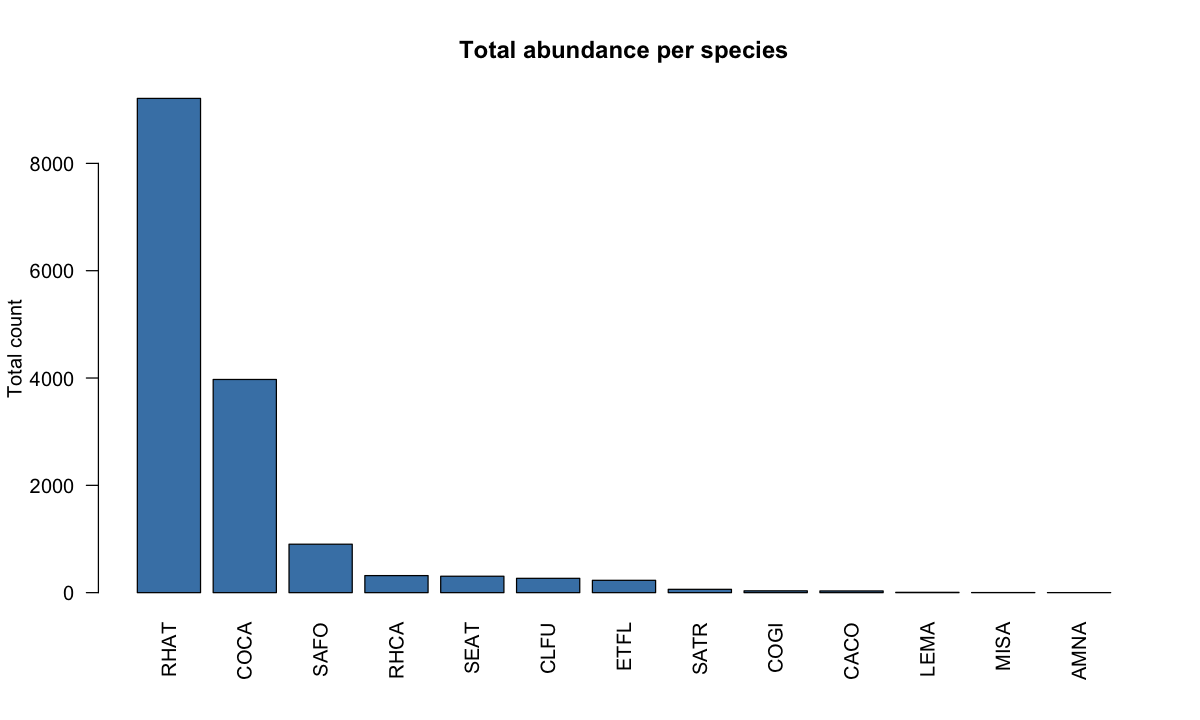

In [43]:
options(repr.plot.width = 10, repr.plot.height = 6)
barplot(sort(colSums(spe), decreasing = TRUE),
        las = 2, col = "steelblue", ylab = "Total count",
        main = "Total abundance per species")

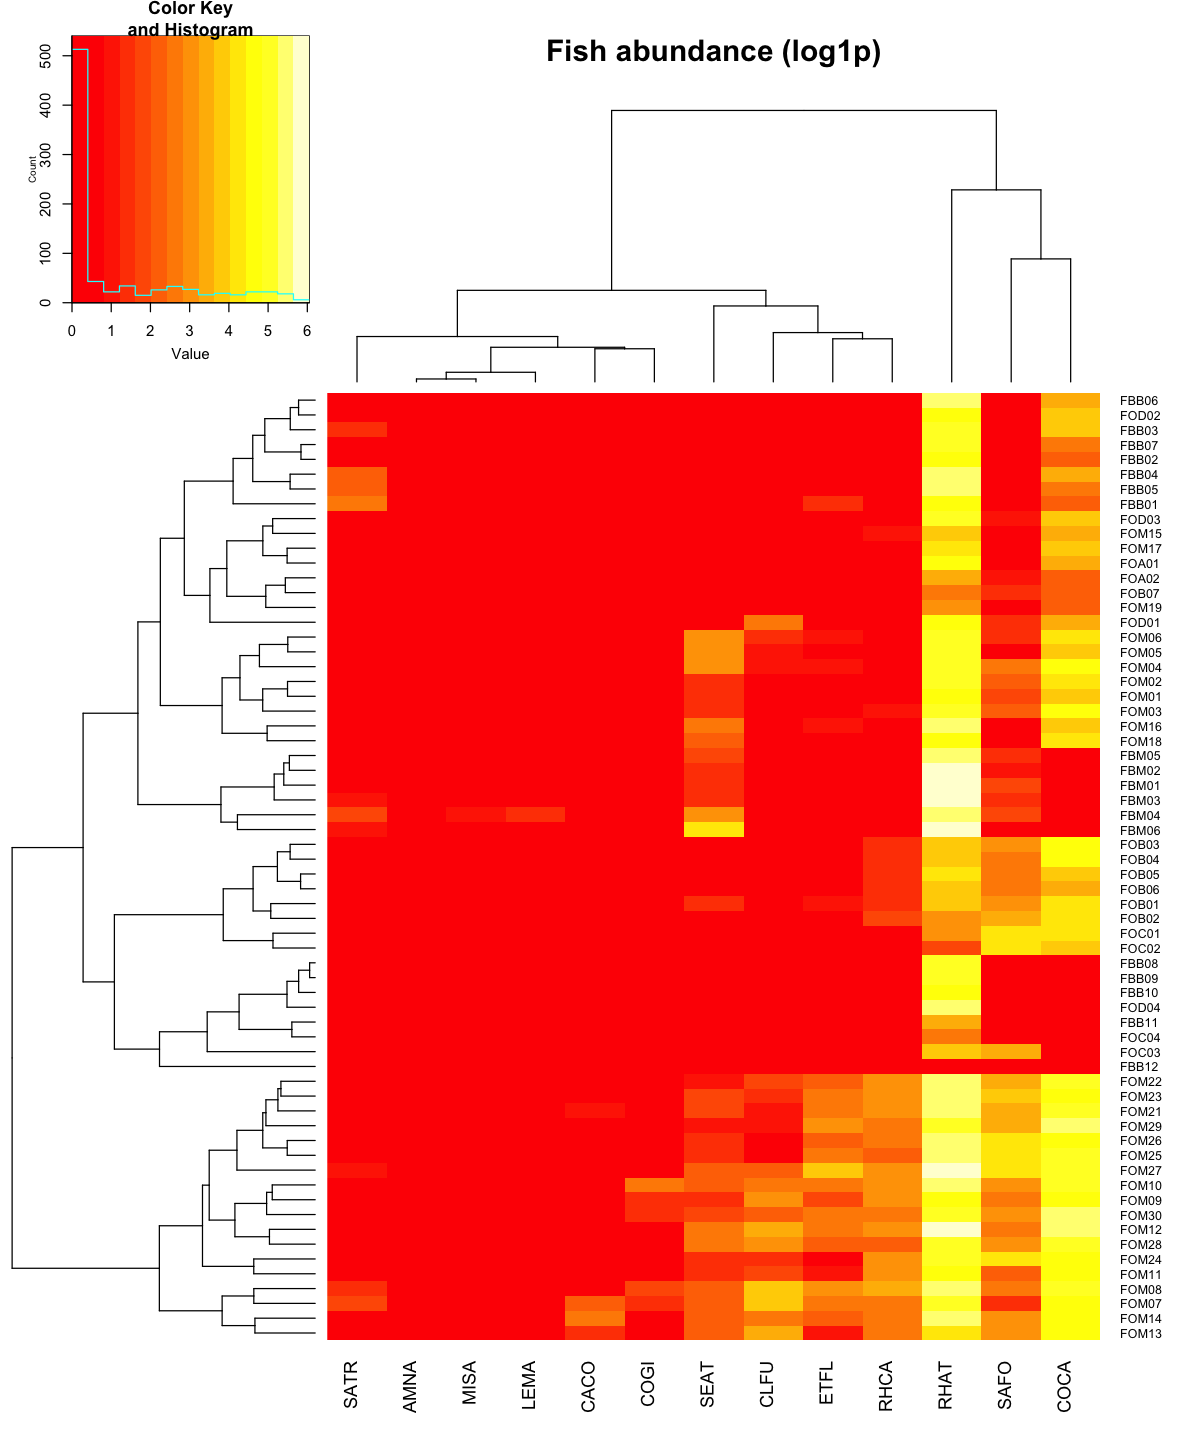

In [44]:
options(repr.plot.width = 10, repr.plot.height = 12)
heatmap.2(as.matrix(log1p(spe)), dendrogram = "both", trace = "none",
          main = "Fish abundance (log1p)") #euclidean distance

**Observations**
- RHAT (~60%) and COCA (~26%) dominate the catch → transform before computing distances.
- Big Hunting reaches (FB…) are species-poor; several have only 1 species.
- Owens mainstem reaches (FOM07–FOM14, FOM21–FOM30) are the richest (up to 10 species).
- AMNA, MISA, LEMA are found in only 1–3 reaches: treat their results with caution.

red = 0, row is a reach (64) column is species (13)
orange = few yellow = many

## Interesting patterns

Brook trout vs brown trout: SAFO is completely absent from all FBB reaches (likely Blue Blazes), and that’s where SATR (brown trout) is most common. Brown trout are known to compete with brook trout, so this could be competition, or simply different habitat. Present it as a pattern worth noting, not a proven cause.

Sculpin missing from the Big Hunting mainstem (FBM) while it’s common in Owens.
Downstream = richer: the lower Owens mainstem has the most species. This is a classic stream pattern: bigger water, more habitat types, more species.

In short, the heatmap shows that fish communities differ clearly between streams and between upstream and downstream sections. 


## 6. Transformations

eg SAFO = 1 instead of 0 , recheck whether or not this raw counts is correct

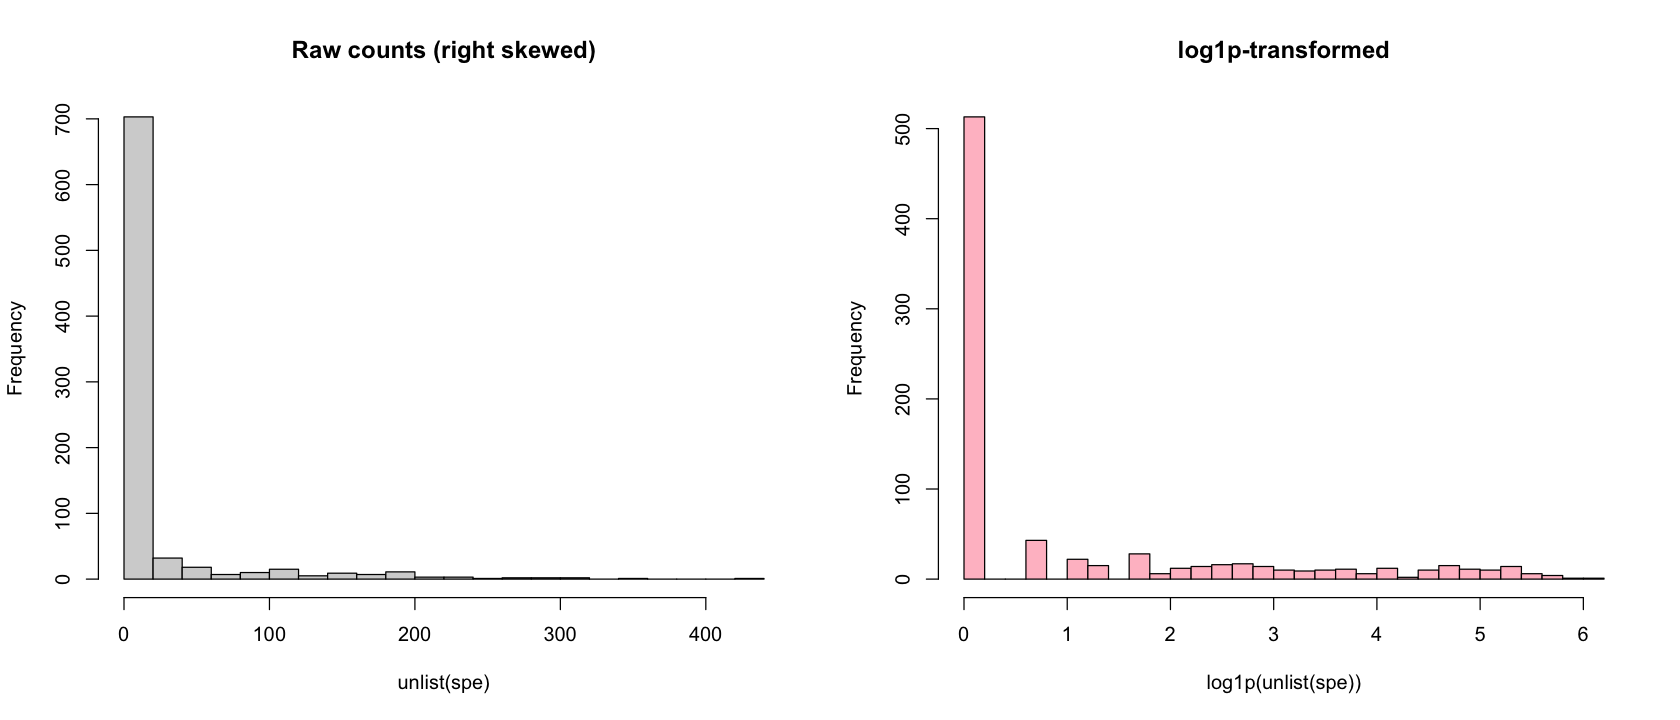

In [45]:
options(repr.plot.width = 14, repr.plot.height = 6)
par(mfrow = c(1, 2))
hist(unlist(spe), breaks = 30, col = "lightgray", main = "Raw counts (right skewed)")
hist(log1p(unlist(spe)), breaks = 30, col = "pink", main = "log1p-transformed")
par(mfrow = c(1, 1))

spe.log <- log1p(spe)                # log(1 + x) same spec in similar amounts?
spe.hel <- decostand(spe, "hel")     # Hellinger, similar relative-makeup of the community?
spe.pa  <- decostand(spe, "pa")      # presence / absence, same species ignoring amounts? jaccard

**Why transform?**

The raw counts (left) are extremely right-skewed: most cells are 0 or small, but a few are very large (up to 423 blacknose dace). On raw counts, distances and correlations would be driven almost entirely by the two dominant species (RHAT and COCA, ~85% of all fish). For example, two reaches with 400 vs 300 dace would look more different than two reaches with 0 vs 5 brook trout, even though the presence of trout says more about a reach.

`log1p(x) = log(1 + x)` compresses large values and spreads out small ones (right), so differences are measured as ratios: 2 → 20 fish counts as much as 20 → 200. Adding 1 keeps zeros at 0, since log(0) = −∞.

The log does not remove the spike at 0 (~510 of 832 cells): most species are absent from most reaches. This is why the distances in section 7 use asymmetric indices (Bray–Curtis, Jaccard) that ignore shared absences, rather than Euclidean distance.

Each transformation prepares the data for one distance in section 7:

| Transformed data | Distance | Question |
|---|---|---|
| `spe.log` (log1p) | Bray–Curtis (main measure of composition) | same species in similar amounts? |
| `spe.hel` (Hellinger) | Hellinger distance (also used later for PCA/RDA) | similar relative community make-up? |
| `spe.pa` (presence/absence) | Jaccard | same species, regardless of amounts? |

## 7. Dissimilarities between reaches

- **Bray–Curtis** (log counts): same species in similar amounts?
- **Jaccard** (presence/absence): same species? Less sensitive to unequal sampling effort.
- **Hellinger**: Euclidean distance on Hellinger-transformed data.
- **Euclidean** (raw): suffers from the double-zero problem; shown for comparison only.

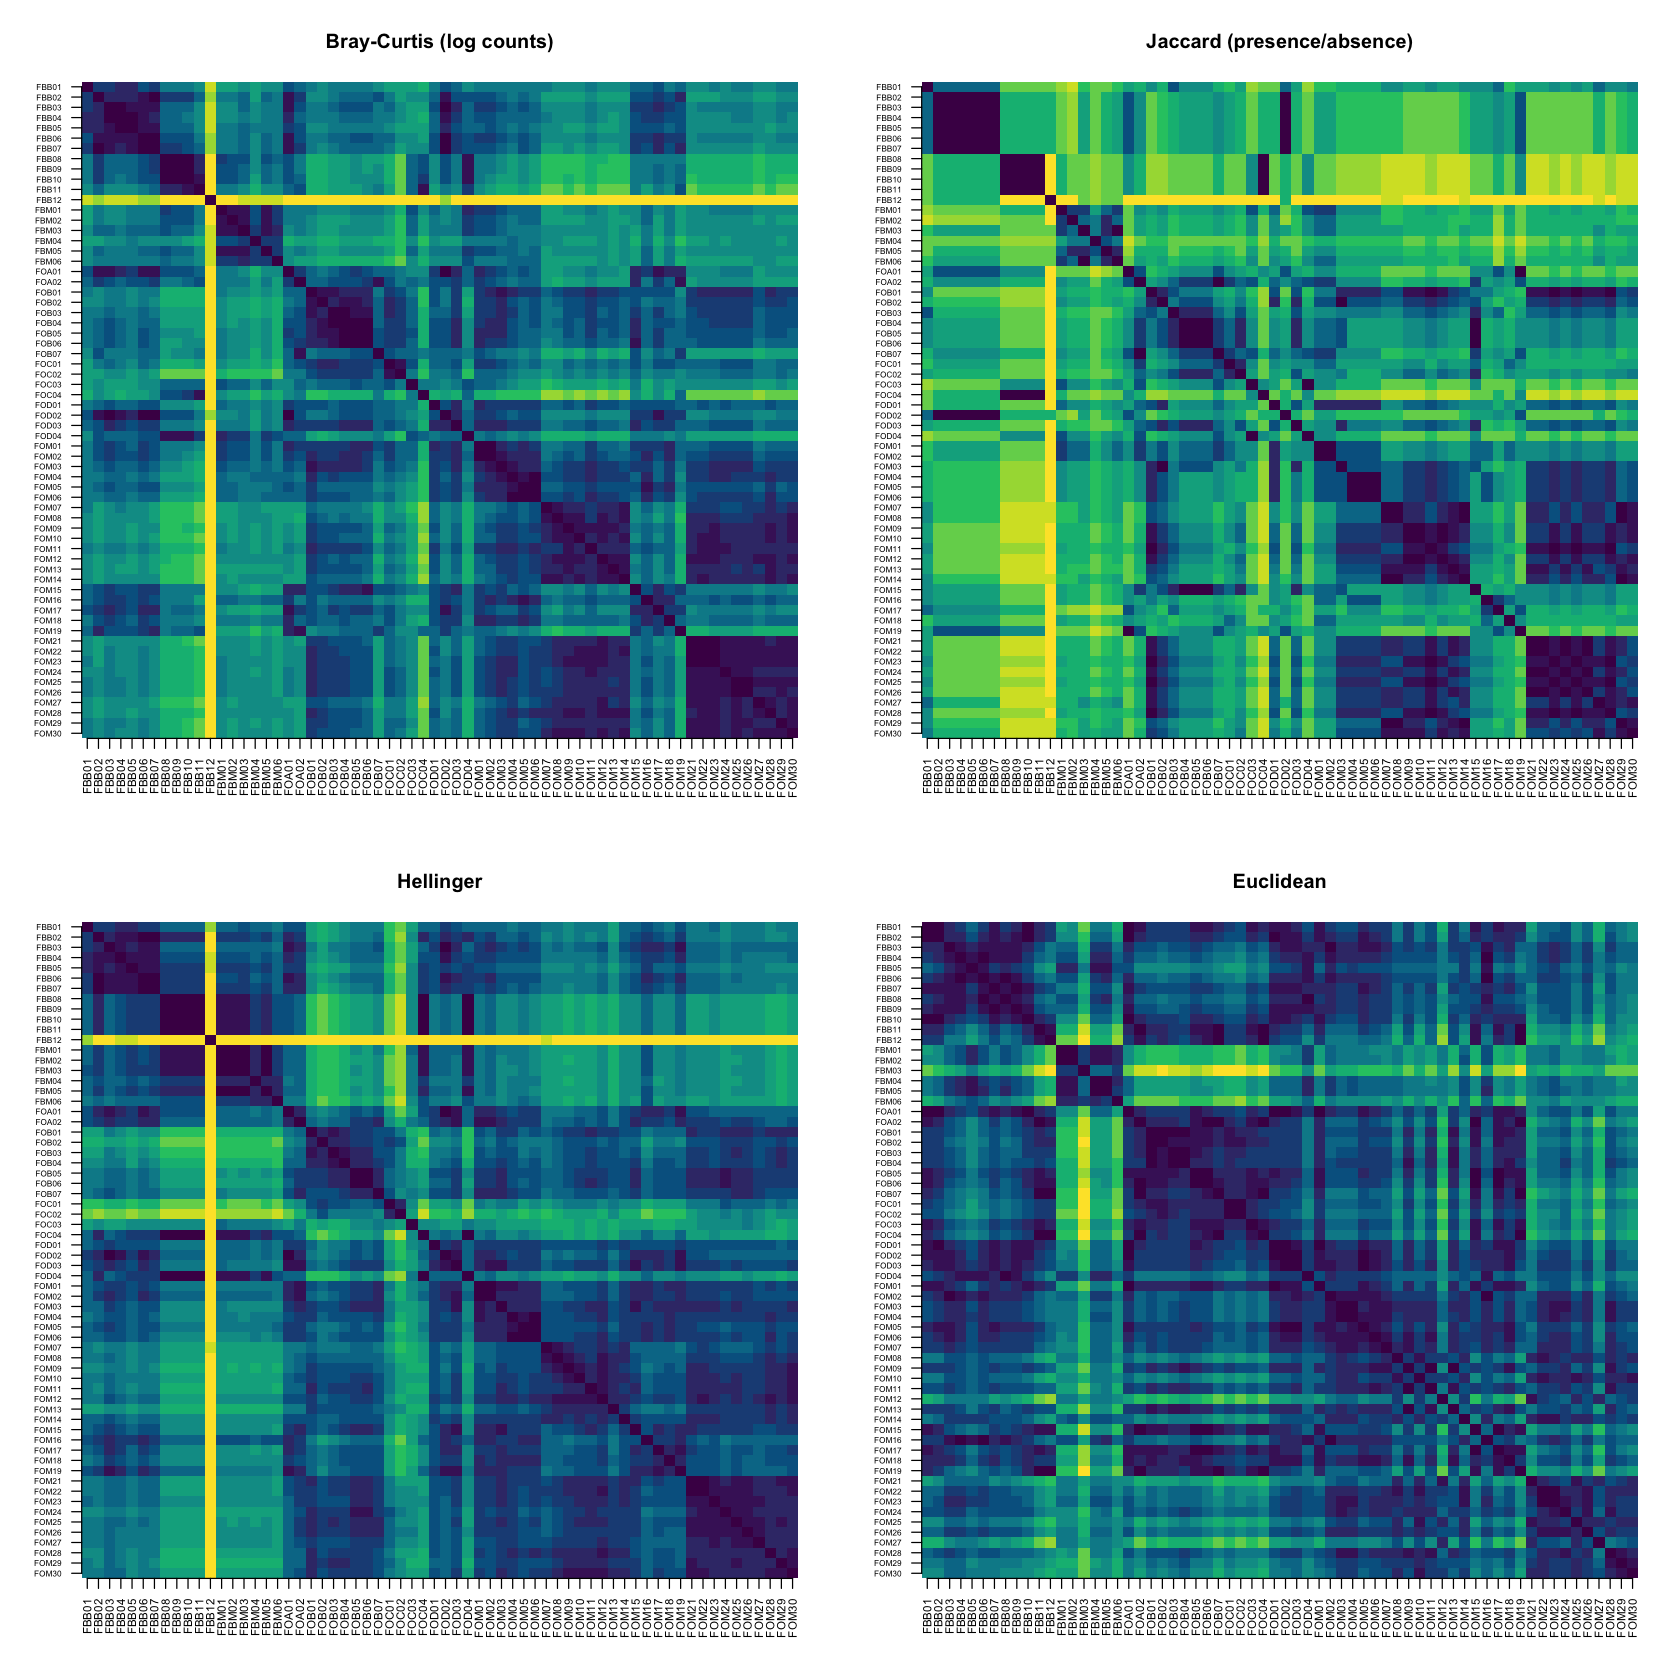

In [46]:
spe.bray <- vegdist(spe.log)                     # Bray-Curtis
spe.jac  <- vegdist(spe, "jac", binary = TRUE)   # Jaccard
spe.dh   <- dist(spe.hel)                        # Hellinger
spe.eucl <- dist(spe)                            # Euclidean

options(repr.plot.width = 14, repr.plot.height = 14)
par(mfrow = c(2, 2))
image.real(spe.bray, "Bray-Curtis (log counts)")
image.real(spe.jac,  "Jaccard (presence/absence)")
image.real(spe.dh,   "Hellinger")
image.real(spe.eucl, "Euclidean")
par(mfrow = c(1, 1))


dark purple = similar, yellow = very different

**Interpretation**

All three ecological distances (Bray–Curtis, Jaccard, Hellinger) show the same structure: dark blocks along the diagonal, meaning neighbouring reaches on the same stream have similar communities (FBB01–07, FOB01–06, and the lower Owens mainstem FOM07–14 + FOM21–30, which also resemble each other).

- **FBB12** (a single brown trout caught) appears as a yellow cross in Bray–Curtis, Jaccard and Hellinger: it shares almost no species with any other reach. In Euclidean distance it looks *similar* to many reaches, because both are mostly zeros: the **double-zero problem**.
- **Euclidean** instead highlights FBM02–06, which have very high dace counts (315–423): it reflects total abundance, not species composition.
- **Jaccard** (presence/absence) gives the sharpest blocks, e.g. dace-only reaches FBB08–11 differ strongly from the species-rich lower Owens.
- **Hellinger** (relative proportions) singles out FOC01–02, dominated by brook trout and sculpin rather than dace.

Because Bray–Curtis, Jaccard and Hellinger agree, the patterns are robust to the choice of index. **Bray–Curtis on log1p counts** is used as the main measure of composition in the rest of the analysis; Euclidean distance is not suitable for this species data.


## 8. Habitat data: cleaning

Habitat was measured right after fishing. A rope runs up the middle of each 100 m reach and **every 5 m** a **transect** is measured straight across the stream (~20 per reach):
- **WettedWidth** (m), **Temp** (°C, one reading at the deepest part)
- at 3 points (**L**eft, **M**iddle, **R**ight, looking downstream): **Depth** (cm), **Mesohabitat** (RIFF / RUN / POOL), **Substrate** top and bottom layer
- **LWD** (woody debris) counts are recorded **once per reach**, not per transect

Substrate codes: BO boulder, CO cobble, GR gravel, SA sand, SI silt, CL clay (BE probably bedrock, MO/MOSS moss — not in metadata).

In [47]:
str(habitat)

hab <- habitat
hab$X <- NULL; hab$X.1 <- NULL                    # empty Excel columns
hab$DepthL          <- as.numeric(hab$DepthL)
hab$LWD.Small.Count <- suppressWarnings(as.numeric(hab$LWD.Small.Count))

# Fix typos in category columns: trailing spaces and lower case ("CO " -> "CO")
cat_cols <- grep("^Mesohabitat|^Substrate", names(hab), value = TRUE)
hab[cat_cols] <- lapply(hab[cat_cols], function(x) toupper(trimws(x)))
lapply(hab[cat_cols], table)

'data.frame':	1225 obs. of  25 variables:
 $ Date                : chr  "7/2/2015" "7/2/2015" "7/2/2015" "7/2/2015" ...
 $ Time                : chr  "10:17:00 AM" "10:17:00 AM" "10:17:00 AM" "10:17:00 AM" ...
 $ Watershed           : chr  "Owens" "Owens" "Owens" "Owens" ...
 $ ReachID             : chr  "FOD01" "FOD01" "FOD01" "FOD01" ...
 $ Transect            : int  1 2 3 4 5 6 7 8 9 10 ...
 $ WettedWidth         : num  2 1.9 1.7 3.9 3.2 2.2 1.1 1.2 1.4 2.3 ...
 $ MesohabitatL        : chr  "RUN" "RUN" "RUN" "RIFF" ...
 $ MesohabitatM        : chr  "RUN" "RIFF" "RUN" "RIFF" ...
 $ MesohabitatR        : chr  "RUN" "RIFF" "RUN" "RUN" ...
 $ DepthL              : num  5.6 11.2 2.8 4.1 5.3 12.3 5.3 14.8 10.5 4.2 ...
 $ DepthM              : num  8.2 12.7 6.3 4.5 12.1 3.3 7 14.2 19.2 6.9 ...
 $ DepthR              : num  8.8 5 9 5.4 6.8 5.5 5.8 13.6 24.1 18.1 ...
 $ SubstrateTopL       : chr  "CO" "CO" "CO" "CO" ...
 $ SubstrateBottomL    : chr  "SA" "SA" "GR" "GR" ...
 $ SubstrateTopM  

$MesohabitatL

POOL RIFF  RUN 
 264  239  713 

$MesohabitatM

POOL  R5U RIFF  RUN 
 189    1  338  692 

$MesohabitatR

POOL RIFF  RUN 
 250  276  695 

$SubstrateTopL

 BE  BO  CL  CO  GR  SA  SI 
  7 325   1 608 172  32  73 

$SubstrateBottomL

 BE  BO  CL  CO  GR  RO  SA  SI 
 30  85  17  64 663   1 314  46 

$SubstrateTopM

  BE   BO   CL   CO   GR   MO MOSS   SA   SI 
   6  363    1  624  176    2    1   26   26 

$SubstrateBottomM

 BE  BO  CL  CO  GR  RO  SA  SI 
 32  99  15  76 676   1 310  16 

$SubstrateTopR

  BE   BO   CL   CO   GR MOSS   SA   SI 
   5  345    1  598  189    3   30   54 

$SubstrateBottomR

 BE  BO  CL  CO  GR   S  SA  SI 
 30  98  18  76 615   2 358  28 


out of 1220 

In [48]:
# Values not described in the metadata
hab[cat_cols] <- lapply(hab[cat_cols], function(x) { x[x == "MO"] <- "MOSS"; x })
meso_cols <- grep("^Mesohabitat", names(hab), value = TRUE)
sum(unlist(hab[meso_cols]) == "R5U", na.rm = TRUE)   # how many R5U entries
hab[meso_cols] <- lapply(hab[meso_cols], function(x) { x[x == "R5U"] <- NA; x })   # only RIFF/RUN/POOL are valid

[1] 1

## 9. Habitat correlations (R-mode)

,WettedWidth,DepthL,DepthM,DepthR,Temp,LWD.Small.Count,LWD.Large.Count
WettedWidth,1.00,0.15,0.07,0.14,-0.04,0.30,0.13
DepthL,0.15,1.00,0.65,0.41,-0.07,-0.01,-0.09
DepthM,0.07,0.65,1.00,0.59,-0.08,-0.06,0.05
DepthR,0.14,0.41,0.59,1.00,-0.08,-0.13,-0.05
Temp,-0.04,-0.07,-0.08,-0.08,1.00,0.02,-0.09
LWD.Small.Count,0.30,-0.01,-0.06,-0.13,0.02,1.00,0.33
LWD.Large.Count,0.13,-0.09,0.05,-0.05,-0.09,0.33,1.00


,WettedWidth,DepthL,DepthM,DepthR,Temp,LWD.Small.Count,LWD.Large.Count
WettedWidth,1.00,0.29,0.17,0.27,-0.10,0.06,0.10
DepthL,0.29,1.00,0.58,0.43,-0.13,0.04,0.01
DepthM,0.17,0.58,1.00,0.57,-0.12,-0.04,0.18
DepthR,0.27,0.43,0.57,1.00,-0.08,-0.17,0.08
Temp,-0.10,-0.13,-0.12,-0.08,1.00,0.04,0.05
LWD.Small.Count,0.06,0.04,-0.04,-0.17,0.04,1.00,0.23
LWD.Large.Count,0.10,0.01,0.18,0.08,0.05,0.23,1.00


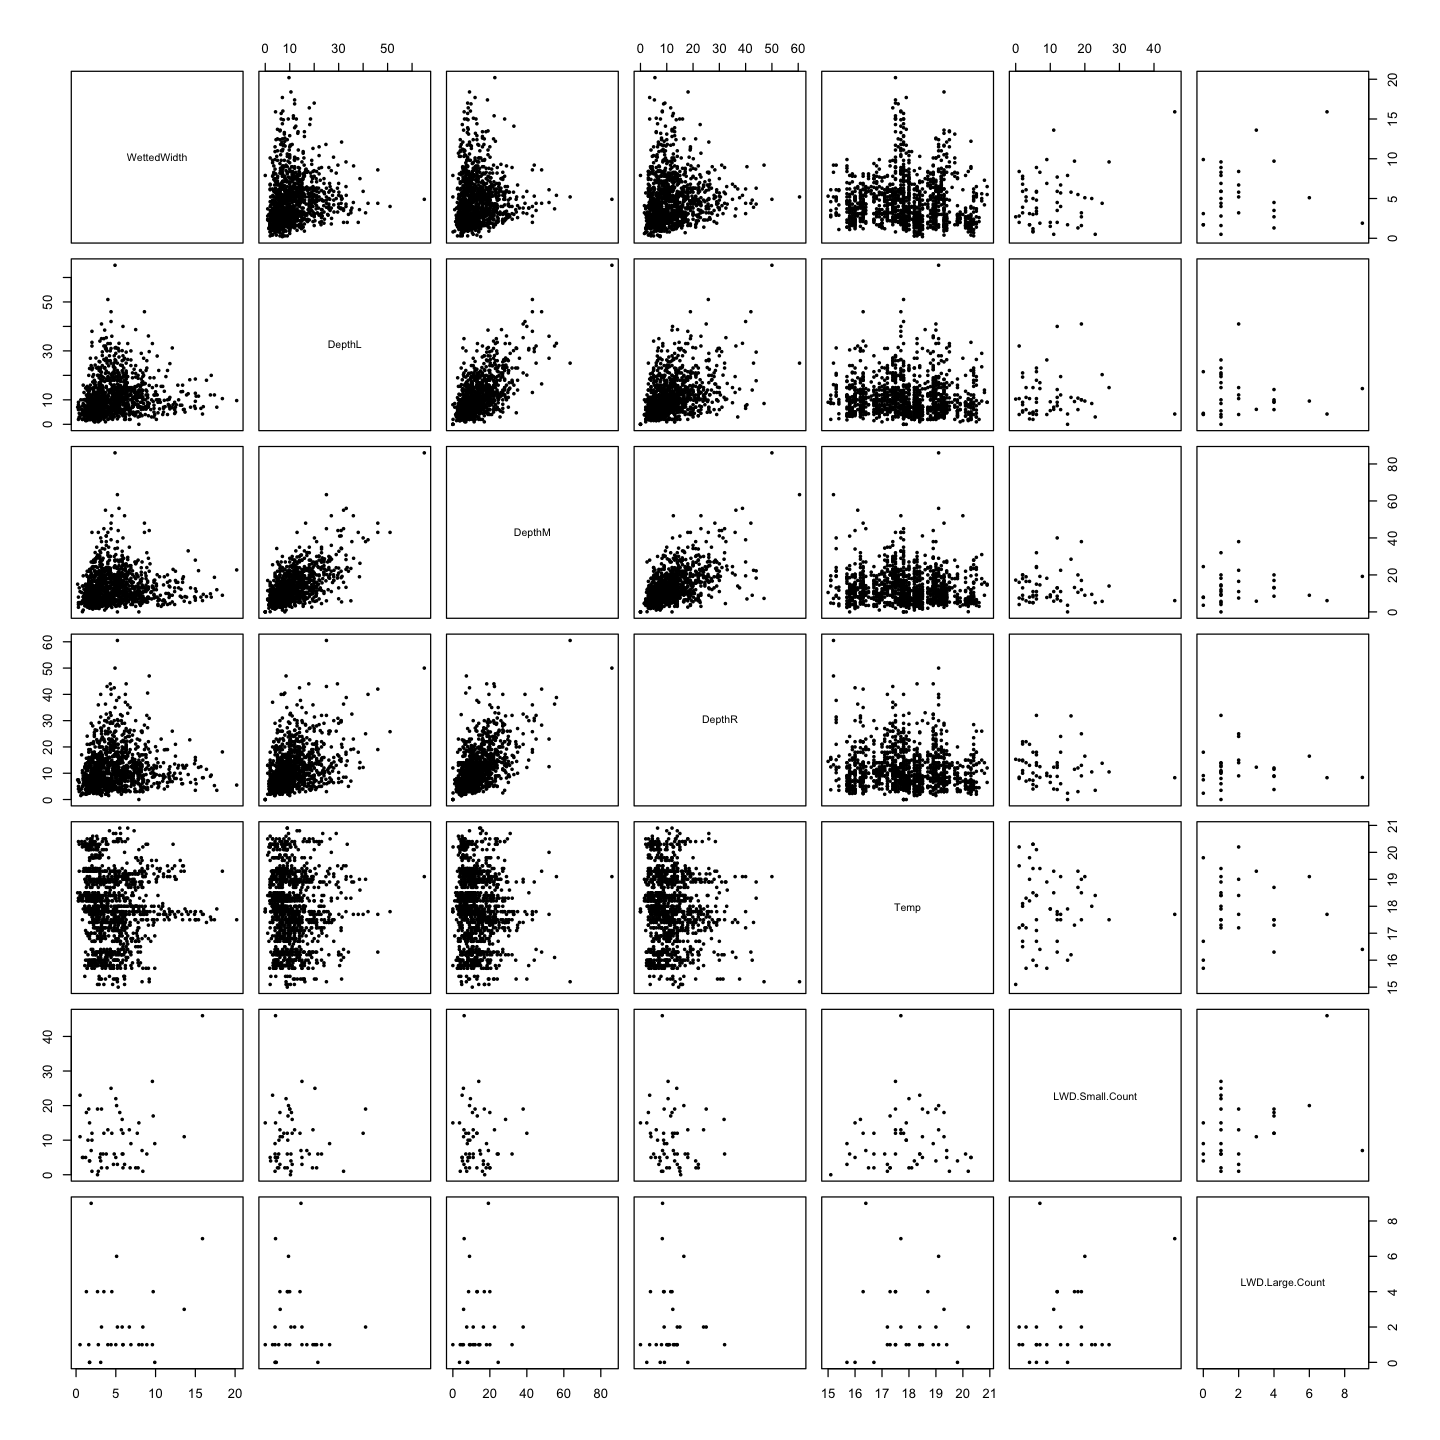

In [49]:
env <- hab[sapply(hab, is.numeric)]
env$Transect <- NULL                     # just a row number, not a habitat variable

round(cor(env, use = "pairwise.complete.obs"), 2)                        # Pearson
round(cor(env, method = "spearman", use = "pairwise.complete.obs"), 2)   # Spearman

options(repr.plot.width = 12, repr.plot.height = 12)
pairs(env, pch = 19, cex = 0.4)

**Observations:** the three depths go together (rho ≈ 0.4–0.65), small woody debris is weakly linked to width (0.30); everything else ≈ 0.
**Interpretation (transect level, n ≈ 1,200)**

- The three depth measurements are moderately correlated (Spearman 0.43–0.58); the middle depth correlates most with both sides, left vs right least. They are partly redundant, so they are averaged into one depth variable later.
- Wetted width is only weakly related to depth (0.17–0.29): wide transects are not necessarily deep (e.g. riffles vs pools), so width and depth carry different information.
- Temperature is unrelated to channel shape (|rho| ≤ 0.13); it varies mainly between reaches and with sampling time, not between transects.
- Woody debris (LWD) was counted once per reach, so it appears on only one transect per reach; its correlations here rest on few rows and are not interpreted (Pearson 0.30 vs Spearman 0.06 with width shows an outlier effect). LWD is analysed at reach level instead.
- Pearson and Spearman largely agree; Spearman is preferred because the variables are skewed.

Overall, apart from depth, the habitat variables are largely independent of each other, so each adds distinct information about the stream.

## 10. Gower distance between transects (mixed data)

`daisy()` needs categories as **factors**. 1225 transects would be unreadable, so we look at one reach (FOD01).

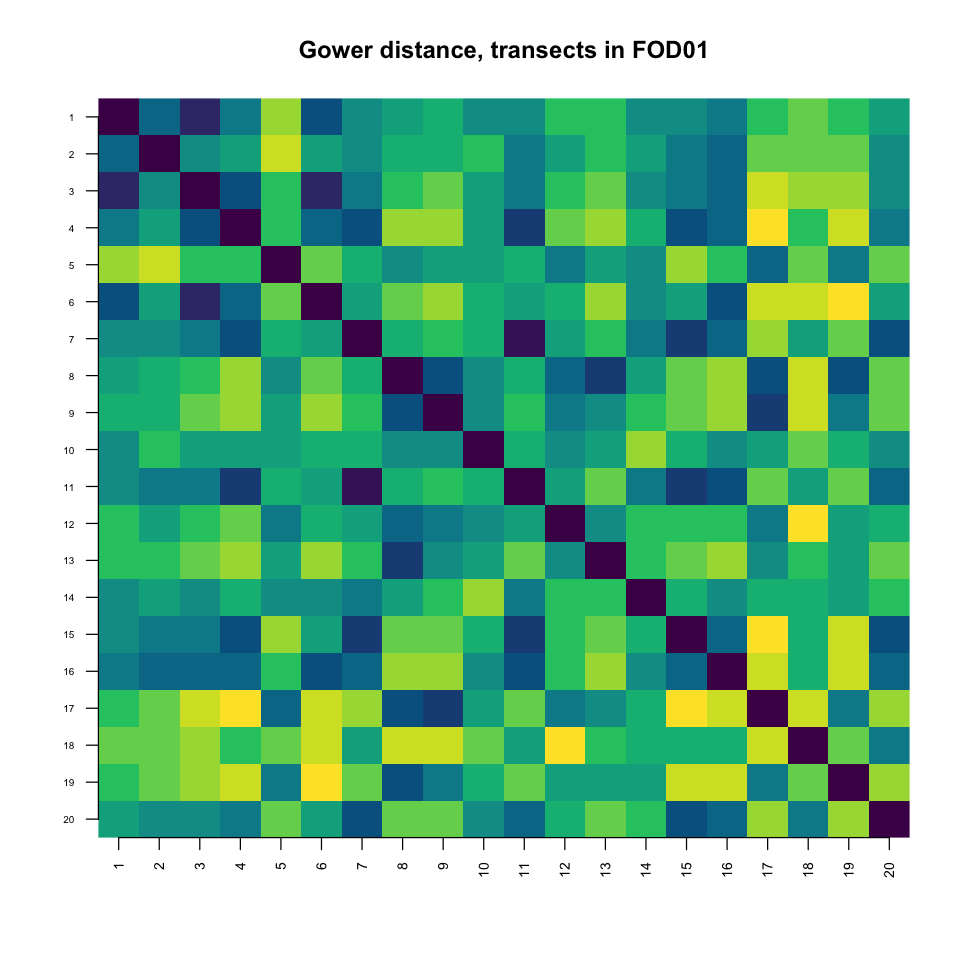

In [50]:
hab.g <- hab[, !(names(hab) %in% c("Date", "Time", "ReachID", "Transect"))]
hab.g[] <- lapply(hab.g, function(col) if (is.character(col)) factor(col) else col)

sub <- hab.g[hab$ReachID == "FOD01", ]
sub <- sub[, colSums(!is.na(sub)) > 0]     # drop columns empty in this reach
hab.gower <- daisy(sub, metric = "gower")

options(repr.plot.width = 8, repr.plot.height = 8)
image.real(hab.gower, "Gower distance, transects in FOD01")

Habitat varies a lot between transects within the same reach (many yellow cells).
**Interpretation**

Gower distance combines numeric variables (difference scaled by the variable's range) and categorical variables (0 = same, 1 = different), averaged over all variables, so it suits this mixed habitat data. Transects are numbered from the downstream end (1) to ~95 m upstream (20).

- There is no clear dark band along the diagonal: neighbouring transects 5 m apart are often already different. Habitat changes in patches (alternating riffles, runs and pools) rather than gradually along the reach.
- Some pairs are strongly different (e.g. transects 4–17, 6–19, 12–18), while most pairs are moderately different (mid-range colours). Colours are scaled to this reach's own range.
- A single 100 m reach therefore contains a mix of habitats. When transects are summarised per reach (section 11), means hide this variation, which is why categorical variables are summarised as **proportions** (% riffle, % cobble…) rather than the most frequent category.
- Only one reach (FOD01) is shown; within-reach heterogeneity may differ between reaches and could itself be tested as an explanatory variable.

## 11. Habitat per reach (`env_reach`)

Fish are counted per **reach**, habitat per **transect** (~20 per reach). To compare them, each reach's transects are summarised into **one row**:
- numbers (depth, width, temperature) → **mean**
- categories (substrate, mesohabitat) → **proportion** of measurements in each category
- woody debris (one value per reach) → that value (its mean is the same value)

In [51]:
# Numeric variables: mean per reach
env_site <- aggregate(env, by = list(ReachID = hab$ReachID), FUN = mean, na.rm = TRUE)
env_site[is.na(env_site)] <- NA   # NaN (no value recorded) -> NA

# Categories: proportions per reach, pooling the L, M and R points
reach3    <- rep(hab$ReachID, 3)
substrate <- c(hab$SubstrateTopL, hab$SubstrateTopM, hab$SubstrateTopR)
meso      <- c(hab$MesohabitatL,  hab$MesohabitatM,  hab$MesohabitatR)

sub_prop  <- as.data.frame.matrix(prop.table(table(reach3, substrate), 1))
meso_prop <- as.data.frame.matrix(prop.table(table(reach3, meso), 1))

env_reach <- cbind(env_site,
                   sub_prop[env_site$ReachID, ],
                   meso_prop[env_site$ReachID, ])

# Same row order as spe
setdiff(rownames(spe), env_reach$ReachID)   # should be empty
env_reach <- env_reach[match(rownames(spe), env_reach$ReachID), ]
rownames(env_reach) <- rownames(spe)   # reaches without habitat data stay as NA rows
env_reach$ReachID   <- rownames(spe)
head(env_reach)

[1] "FBM02" "FOB01" "FOB02" "FOM18"

,ReachID,WettedWidth,DepthL,DepthM,DepthR,Temp,LWD.Small.Count,LWD.Large.Count,BE,BO,CL,CO,GR,MOSS,SA,SI,POOL,RIFF,RUN
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FBB01,FBB01,2.776471,9.970588,14.423529,11.158824,19.03529,4,NA,0.00000000,0.01960784,0.00000000,0.3333333,0.6078431,0,0.03921569,0.00000000,0.2941176,0.29411765,0.4117647
FBB02,FBB02,2.257895,7.063158,10.321053,9.694737,19.36316,5,NA,0.00000000,0.12280702,0.05263158,0.5789474,0.2105263,0,0.03508772,0.00000000,0.1929825,0.21052632,0.5964912
FBB03,FBB03,2.176190,7.000000,8.928571,7.880952,19.31429,1,NA,0.01587302,0.28571429,0.00000000,0.4761905,0.1746032,0,0.04761905,0.00000000,0.3174603,0.09523810,0.5873016
FBB04,FBB04,2.555000,6.650000,7.925000,7.600000,19.83000,4,0,0.00000000,0.00000000,0.00000000,0.8333333,0.1166667,0,0.00000000,0.05000000,0.1833333,0.21666667,0.6000000
FBB05,FBB05,2.105000,6.950000,8.400000,6.725000,20.23500,6,NA,0.01666667,0.11666667,0.00000000,0.5666667,0.2166667,0,0.05000000,0.03333333,0.3000000,0.06666667,0.6333333
FBB06,FBB06,2.205000,8.010000,8.090000,7.065000,20.19000,5,NA,0.00000000,0.18333333,0.00000000,0.6000000,0.2000000,0,0.00000000,0.01666667,0.1500000,0.28333333,0.5666667


In [65]:
# Habitat heterogeneity: coefficient of variation (sd / mean) per reach
cv <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) < 2) return(NA)
  sd(x) / mean(x)
}

hab$DepthAvg <- rowMeans(hab[, c("DepthL", "DepthM", "DepthR")], na.rm = TRUE)   # mean depth per transect

env_cv <- aggregate(hab[, c("WettedWidth", "DepthAvg")],
                    by = list(ReachID = hab$ReachID), FUN = cv)
names(env_cv) <- c("ReachID", "CV_Width", "CV_Depth")

# Add to env_reach in the same row order
env_reach$CV_Width <- env_cv$CV_Width[match(env_reach$ReachID, env_cv$ReachID)]
env_reach$CV_Depth <- env_cv$CV_Depth[match(env_reach$ReachID, env_cv$ReachID)]
head(env_reach[, c("ReachID", "WettedWidth", "CV_Width", "DepthM", "CV_Depth")])

,ReachID,WettedWidth,CV_Width,DepthM,CV_Depth
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
FBB01,FBB01,2.776471,0.5126139,14.423529,1.2729659
FBB02,FBB02,2.257895,0.4005965,10.321053,0.4612579
FBB03,FBB03,2.176190,0.4944695,8.928571,0.4746872
FBB04,FBB04,2.555000,0.2280317,7.925000,0.4139101
FBB05,FBB05,2.105000,0.3738954,8.400000,0.3862954
FBB06,FBB06,2.205000,0.3532806,8.090000,0.5787102


## 12. Fish vs habitat

coefficient of variation. Since mean only tells you how deep/wide a reach is on average. CV = how much width/depth along the reach

Low CV = every transect is the same, so uniform channel
High CV = habitat varied

Gower plot = shows habitat changes a lot within a reach and because we average , this is hidden now

In [66]:
# Are more variable reaches richer in species?
round(cor(richness, env_reach[, c("CV_Width", "CV_Depth")],
          method = "spearman", use = "pairwise.complete.obs"), 2)

CV_Width,CV_Depth
-0.37,-0.23


In [67]:
# 1. Is CV linked to stream size?
round(cor(env_reach[, c("CV_Width", "CV_Depth")], env_reach[, c("WettedWidth", "DepthM")],
          method = "spearman", use = "pairwise.complete.obs"), 2)

# 2. Significance of the richness correlations
cor.test(richness, env_reach$CV_Width, method = "spearman", exact = FALSE)
cor.test(richness, env_reach$CV_Depth, method = "spearman", exact = FALSE)

# 3. Does heterogeneity matter once size and effort are accounted for?
mod_cv <- lm(richness ~ eff + env_reach$DepthM + env_reach$CV_Width + env_reach$CV_Depth)
summary(mod_cv)

,WettedWidth,DepthM
CV_Width,-0.32,-0.41
CV_Depth,-0.34,-0.24



	Spearman's rank correlation rho

data:  richness and env_reach$CV_Width
S = 49170, p-value = 0.004004
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.3662263 



	Spearman's rank correlation rho

data:  richness and env_reach$CV_Depth
S = 44288, p-value = 0.07633
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.2305724 



Call:
lm(formula = richness ~ eff + env_reach$DepthM + env_reach$CV_Width + 
    env_reach$CV_Depth)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.6327 -0.7243 -0.1234  1.2124  3.5989 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)    
(Intercept)        -0.8930299  1.1083348  -0.806  0.42386    
eff                 0.0024987  0.0004805   5.200 3.02e-06 ***
env_reach$DepthM    0.1941980  0.0569033   3.413  0.00121 ** 
env_reach$CV_Width  0.0663124  2.1759444   0.030  0.97580    
env_reach$CV_Depth  0.5783192  1.2850407   0.450  0.65445    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.438 on 55 degrees of freedom
  (4 observations deleted due to missingness)
Multiple R-squared:  0.7254,	Adjusted R-squared:  0.7054 
F-statistic: 36.31 on 4 and 55 DF,  p-value: 7.714e-15


### Habitat heterogeneity: is the negative correlation real?

Richness was negatively correlated with the coefficient of variation (CV = SD / mean) of width (rho = −0.37) and depth (rho = −0.23). Because CV divides by the mean, it may simply reflect stream size.

---

#### 1. Is CV linked to stream size? (2 × 2 correlation matrix)

Each cell is the Spearman correlation between one CV variable (rows) and one size variable (columns), across reaches:

|  | Mean wetted width | Mean middle depth |
|---|---|---|
| **CV of width** | −0.32 | −0.41 |
| **CV of depth** | −0.34 | −0.24 |

- **All four values are negative:** the smaller (narrower, shallower) a reach, the more variable it is *relative to its size*.
- This is expected from how CV is calculated: in a small stream the mean is small, so even modest absolute variation (e.g. one pool in an otherwise shallow reach) gives a large CV. Example: FBB01 has a CV of depth of 1.27, meaning depth varies by more than its own average.
- **Conclusion:** CV is partly a measure of stream size in disguise (high CV ≈ small stream).

---

#### 2. Are the richness correlations significant? (`cor.test`)

| Test | rho | p | Significant? |
|---|---|---|---|
| Richness vs CV of width | −0.37 | 0.004 | Yes (p < 0.05) |
| Richness vs CV of depth | −0.23 | 0.076 | No (p > 0.05; marginal) |

- **rho** = Spearman correlation (−1 to +1); negative means reaches with more variable width/depth have *fewer* species.
- **p** = probability of a correlation this strong arising by chance if there were truly no relationship. Below 0.05 is conventionally treated as significant.
- **S** is the test statistic used to compute p (based on the differences between the two rankings); it is not interpreted directly.
- On its own, CV of width is significantly (negatively) related to richness; CV of depth is not.

---

#### 3. Does heterogeneity matter once stream size and effort are accounted for? (linear model)

`lm(richness ~ effort + DepthM + CV_Width + CV_Depth)`: each coefficient is the effect of that variable **while holding all the others constant**.

| Term | Estimate | Std. error | t | p | Interpretation |
|---|---|---|---|---|---|
| Intercept | −0.89 | 1.11 | −0.81 | 0.42 | Richness when all predictors are 0; not meaningful |
| Effort | 0.0025 | 0.0005 | 5.20 | < 0.001 *** | ≈ +1.5 species per 10 min of electrofishing |
| Mean middle depth | 0.19 | 0.06 | 3.41 | 0.001 ** | ≈ +2 species per 10 cm deeper |
| CV of width | 0.07 | 2.18 | 0.03 | **0.98** | no effect |
| CV of depth | 0.58 | 1.29 | 0.45 | **0.65** | no effect |

How to read the columns:
- **Estimate:** change in species richness for a one-unit increase in that variable, others held constant.
- **Std. error:** uncertainty of the estimate. For the CV terms the standard errors (2.18 and 1.29) are many times larger than the estimates, i.e. the data cannot distinguish their effect from zero.
- **t value** = estimate ÷ standard error. Values far from 0 (roughly beyond ±2) indicate a clear effect; the CV terms have t ≈ 0.03 and 0.45.
- **Pr(>|t|):** the p-value for each term.

Once effort and depth are in the model, **both CV terms are far from significant (p = 0.98 and 0.65)**, and their signs even turn positive. The negative correlations from step 2 disappear.

**Model fit** (compared with the model without CVs, section 13):

| | Without CVs | With CVs |
|---|---|---|
| R² | 0.724 | 0.725 |
| Adjusted R² | 0.714 | **0.705** |
| Residual standard error | 1.415 | 1.438 |

- **R²** (share of variation in richness explained) barely increases (+0.001), as it always does slightly when variables are added.
- **Adjusted R²** penalises extra variables that do not help; it **decreases**, meaning the CV terms add complexity without explanatory value.
- **Residual standard error** (typical prediction error, in species) gets slightly worse.
- **F-statistic** (36.3, p < 0.001): the model as a whole is significant, entirely because of effort and depth.
- **"4 observations deleted due to missingness":** the 4 reaches without habitat data (FBM02, FOB01, FOB02, FOM18); the model uses 60 reaches (55 degrees of freedom = 60 − 5 estimated coefficients).

---

#### Conclusion

The negative correlation between habitat heterogeneity (CV) and species richness is **a by-product of stream size**: small streams have high relative variability *and* few species. Once stream depth and sampling effort are accounted for, within-reach variability in width and depth has **no independent effect** on species richness. CV is therefore not used as an additional predictor.

*Caveat:* CV is a scale-dependent measure of heterogeneity. Other measures, such as the standard deviation of depth, the mean within-reach Gower distance (section 10), or the diversity of mesohabitat types, might capture habitat heterogeneity differently and could be tested in future work.

WettedWidth,DepthL,DepthM,DepthR,Temp,LWD.Small.Count,LWD.Large.Count,BE,BO,CL,CO,GR,MOSS,SA,SI,POOL,RIFF,RUN
0.55,0.79,0.8,0.82,-0.1,-0.22,0.09,0.07,0.33,-0.11,0.19,-0.33,0.16,-0.23,-0.41,-0.11,0.27,-0.18


,WettedWidth,DepthL,DepthM,DepthR,Temp,LWD.Small.Count,LWD.Large.Count,BE,BO,CL,CO,GR,MOSS,SA,SI,POOL,RIFF,RUN
AMNA,0.19,0.20,0.16,0.16,0.14,0.01,-0.11,-0.06,0.14,-0.02,-0.06,-0.12,-0.04,0.18,0.00,0.07,0.03,-0.08
CACO,0.19,0.53,0.50,0.50,-0.24,-0.22,0.04,0.22,0.09,-0.05,0.17,-0.25,0.04,-0.15,-0.15,0.03,0.16,-0.13
CLFU,0.35,0.61,0.63,0.67,-0.09,-0.11,0.20,0.22,0.23,-0.10,0.16,-0.24,0.24,-0.25,-0.27,0.01,0.29,-0.24
COCA,0.36,0.53,0.55,0.59,-0.25,-0.23,-0.04,0.08,0.30,-0.12,0.27,-0.27,0.16,-0.35,-0.40,-0.16,0.23,-0.08
COGI,0.22,0.41,0.41,0.46,0.02,0.00,-0.08,0.03,0.10,-0.06,0.17,-0.12,-0.01,-0.19,-0.39,0.03,0.13,-0.16
ETFL,0.38,0.62,0.64,0.66,-0.10,-0.29,0.12,0.10,0.18,-0.11,0.13,-0.19,0.06,-0.17,-0.21,-0.10,0.18,-0.10
LEMA,0.28,0.21,0.20,0.16,0.23,0.00,-0.15,-0.08,0.08,-0.02,-0.18,0.01,-0.06,0.27,0.13,-0.06,-0.10,0.09
MISA,0.19,0.20,0.16,0.16,0.14,0.01,-0.11,-0.06,0.14,-0.02,-0.06,-0.12,-0.04,0.18,0.00,0.07,0.03,-0.08
RHAT,0.44,0.40,0.39,0.42,0.29,-0.26,0.20,-0.04,0.05,-0.05,0.02,-0.13,-0.13,0.10,0.14,-0.02,-0.18,0.15
RHCA,0.37,0.68,0.72,0.72,-0.33,-0.22,0.02,0.13,0.25,-0.11,0.15,-0.25,0.12,-0.24,-0.39,-0.21,0.30,-0.15


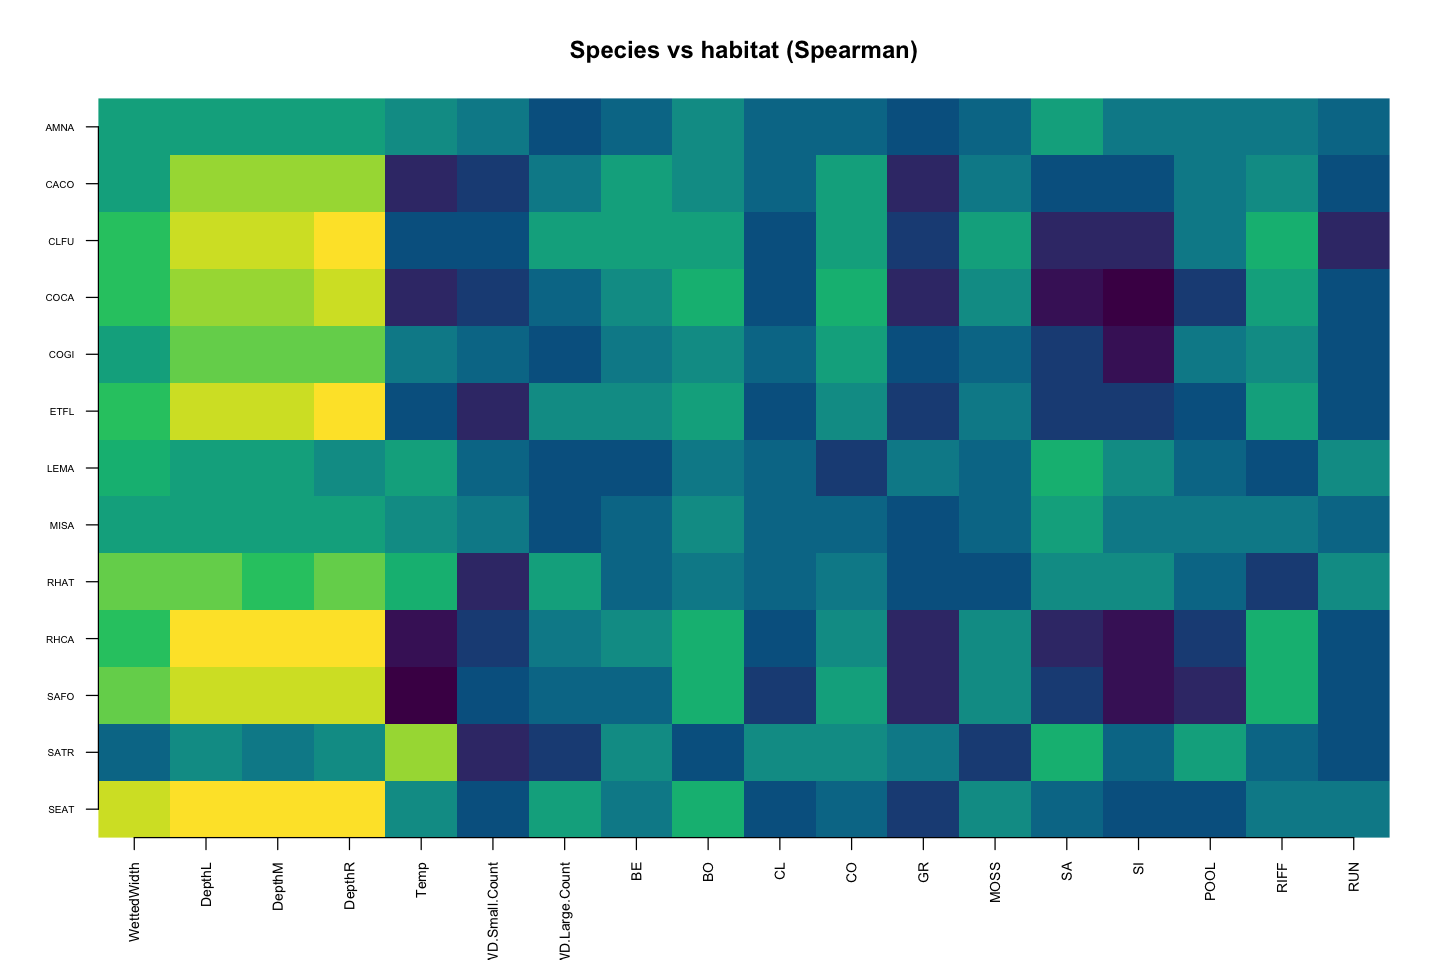

In [52]:
env_num <- env_reach[, -1]   # drop the ReachID text column

# Species richness vs each habitat variable
round(cor(richness, env_num, method = "spearman", use = "pairwise.complete.obs"), 2)

# Each species (log counts) vs each habitat variable
fish_env <- cor(log1p(spe), env_num, method = "spearman", use = "pairwise.complete.obs")
round(fish_env, 2)

options(repr.plot.width = 12, repr.plot.height = 8)
image.real(fish_env, "Species vs habitat (Spearman)")

**Observations**

*Species richness vs habitat* (first output of this cell, Spearman): richness increases with depth (rho = …) and width (rho = …), and decreases with silt (rho = …) and sand (rho = …). Bigger, deeper reaches with clean coarse substrate hold more species. ← fill in from the richness row

*Individual species vs habitat* (table and heatmap; rows = species, yellow = positive, purple = negative):

- **Depth** is the dominant pattern: almost every species is more abundant in deeper reaches (rho ≈ 0.4–0.7 for CACO, CLFU, COCA, COGI, ETFL, RHCA, SAFO, SEAT). The yellow band across the depth columns shows this. Only the rare species and brown trout (SATR, ≈ 0.1) do not follow it.
- **Fine sediment** (silt, sand) is negative for bottom-dwelling species: sculpins (COCA −0.40 with silt, COGI −0.39), longnose dace (RHCA −0.39) and brook trout (SAFO −0.33). These fish live and spawn in the gaps between stones, which fine sediment fills.
- **Riffles** are positive for longnose dace (RHCA 0.30), rosyside dace (CLFU 0.29) and brook trout (SAFO 0.24), species associated with fast-flowing water.
- **Temperature** separates the two trout: brook trout are less abundant in warmer reaches (SAFO −0.48, also RHCA −0.33), while brown trout are more abundant there (SATR +0.56). The SATR result is probably a watershed effect: brown trout occur mainly in Big Hunting, which is warmer (see the plot below).
- **Woody debris** shows only weak, mostly negative correlations (≈ −0.1 to −0.3), so no clear effect at this scale.
- **AMNA and MISA** have identical rows because each was caught in only one reach (FBM04); LEMA in three. Their correlations are not meaningful and are not interpreted.

Caveats: these are 13 × 18 = 234 correlations, so a few moderate values are expected by chance; depth is also strongly correlated with sampling effort (section 13), so part of the depth effect may reflect longer fishing in bigger reaches.

### Temperature vs richness, coloured by watershed


	Spearman's rank correlation rho

data:  env_reach$Temp and richness
S = 39754, p-value = 0.4265
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
-0.104584 


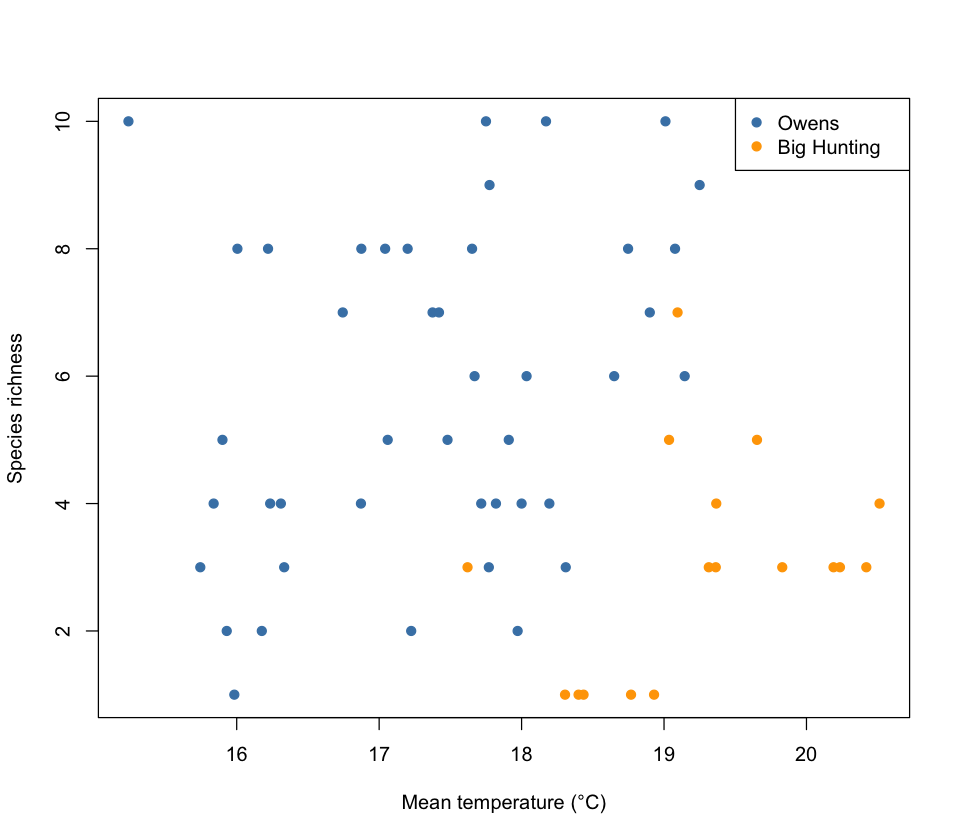

In [53]:
options(repr.plot.width = 8, repr.plot.height = 7)
plot(env_reach$Temp, richness, pch = 19,
     col = ifelse(ws == "Owens", "steelblue", "orange"),
     xlab = "Mean temperature (°C)", ylab = "Species richness")
legend("topright", legend = c("Owens", "Big Hunting"),
       col = c("steelblue", "orange"), pch = 19)

cor.test(env_reach$Temp, richness, method = "spearman", exact = FALSE)

**Interpretation**

Across all 64 reaches, mean temperature is not related to species richness (Spearman rho = −0.10, p = 0.43).

Colouring by watershed shows why the overall pattern is misleading: all Big Hunting reaches (orange, n = 18) lie on the warm side (≈ 17.6–20.5 °C) and are species-poor (mostly 1–5 species), whereas Owens reaches (blue, n = 46) span the full temperature range (≈ 15–19 °C) and richness range (1–10) with no visible trend. Any apparent link between warmth and low richness therefore reflects a difference **between watersheds**, not an effect of temperature within them.

Watershed is a confounding variable: the two creeks differ in temperature, size and species pool at the same time. It is treated as a control variable in the later analyses, and results such as the positive brown-trout–temperature correlation (SATR +0.56) are interpreted with this in mind, since brown trout occur mainly in Big Hunting.

Note: `Temp` is a single spot reading per transect, so it is a noisy measure of a reach's thermal conditions; the logger data would give a more reliable summer temperature.

## 13. Sampling effort (confounder)

Bigger reaches were fished longer, and longer fishing finds more species.

[1] 0.8113842

[1] 0.7885911


Call:
lm(formula = richness ~ eff + env_reach$DepthM)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.6247 -0.6751 -0.1030  1.2011  3.5833 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)      -0.5753803  0.5253678  -1.095 0.278037    
eff               0.0024364  0.0004513   5.398 1.36e-06 ***
env_reach$DepthM  0.1957387  0.0554266   3.531 0.000826 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.415 on 57 degrees of freedom
  (4 observations deleted due to missingness)
Multiple R-squared:  0.7241,	Adjusted R-squared:  0.7144 
F-statistic: 74.81 on 2 and 57 DF,  p-value: < 2.2e-16


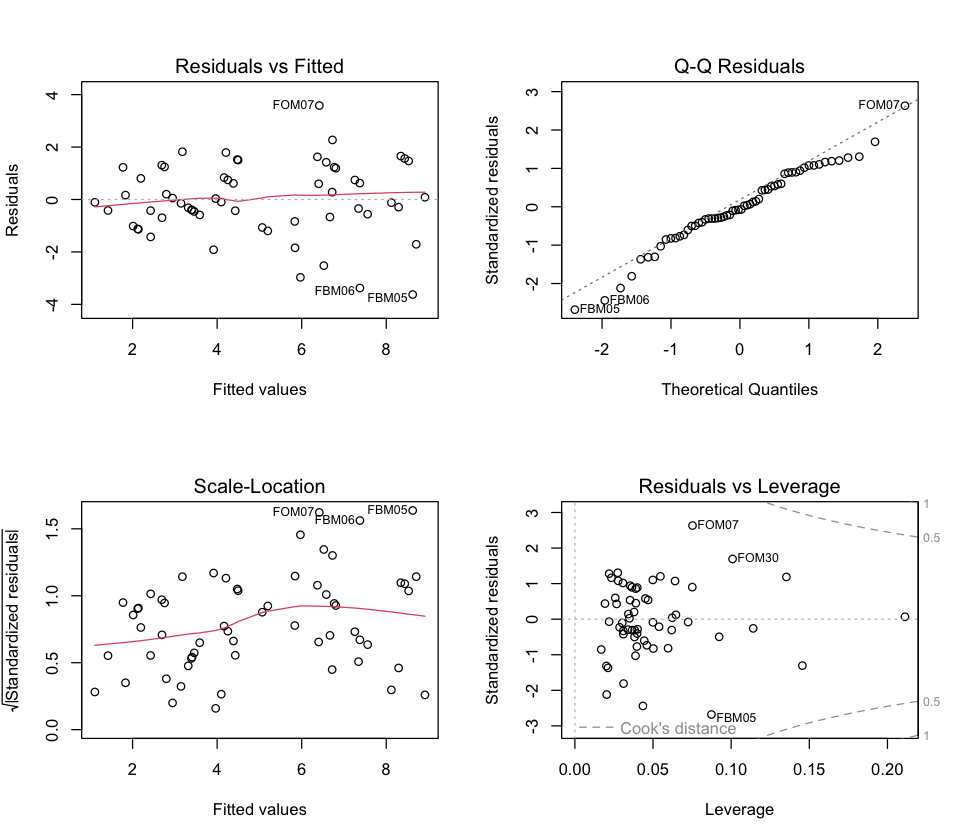

In [54]:
cor(eff, richness, method = "spearman")
cor(eff, env_reach$DepthM, method = "spearman", use = "complete.obs")

# Does depth still matter once effort is accounted for?
mod <- lm(richness ~ eff + env_reach$DepthM)
summary(mod)

par(mfrow = c(2, 2)); plot(mod); par(mfrow = c(1, 1))

0.81: effort vs richness. Longer fishing found more species.
0.79: effort vs depth. Deeper reaches were fished longer.

**Interpretation**

Sampling effort is strongly correlated with both species richness (Spearman rho = 0.81) and depth (rho = 0.79), so the depth–richness relationship could simply reflect longer fishing in bigger reaches.

A linear model including both predictors (n = 60 reaches; 4 without habitat data excluded) shows that **both effort and depth have independent, significant effects** on richness:
- effort: +0.0024 species per second (≈ +1.5 species per 10 min of electrofishing), p < 0.001
- middle depth: +0.20 species per cm (≈ +2 species per 10 cm), p < 0.001

Together they explain 72% of the variation in richness (R² = 0.72). The depth effect is therefore not just an artefact of sampling effort.

Caveats: effort and depth are strongly correlated, which reduces the precision of each estimate. Effort may also partly be a consequence of stream size (bigger reaches take longer to fish), in which case controlling for it removes part of the true size effect and the depth estimate is conservative. Watershed is not included in this model.

**Model diagnostics**

- **Residuals vs Fitted:** residuals are centred on 0 with a nearly flat trend line, so the linear relationship is adequate.
- **Q-Q plot:** residuals follow the normal line closely, with only slight deviations in the tails; normality is reasonable.
- **Scale-Location:** the trend line rises slightly, indicating mild heteroscedasticity (more variable residuals for species-rich reaches), which is typical for count data such as richness.
- **Residuals vs Leverage:** no reach lies beyond Cook's distance 0.5, so no single reach strongly influences the model.

Overall, the assumptions of the linear model are reasonably met.

The largest residuals are informative: FOM07 (lower Owens) has more species than predicted, whereas FBM05 and FBM06 (Big Hunting mainstem) have fewer than predicted for their depth and sampling effort. This is consistent with the watershed effect seen earlier: Big Hunting reaches are poorer in species than their stream size would suggest, so watershed should be considered as an additional predictor.

## 14. Next steps (draft)

In [55]:
# Rarefied richness: expected number of species if 20 fish had been caught everywhere
keep <- rowSums(spe) >= 20
rare <- rarefy(spe[keep, ], sample = 20)
cor(rare, env_reach$DepthM[keep], method = "spearman", use = "complete.obs")

[1] 0.707636

0.707 is a Spearman correlation, between two things measured for each reach:

Rarefied richness: how many species the reach would have if exactly 20 fish had been caught there
Mean middle depth of the reach
Correlations run from −1 to +1:
+1: perfect match. The deeper the reach, the more species, every single time.
0: no relationship.
−1: perfect opposite.

0.71 is a strong positive relationship. If you rank the reaches from shallowest to deepest, and separately from fewest to most species, the two rankings are largely the same. Deeper reaches tend to have more species.
Why it matters: you already knew deeper reaches have more species (raw richness vs depth ≈ 0.76). But deeper reaches also yielded more fish, and catching more fish naturally reveals more species. Rarefaction removes that by putting every reach on the same footing of 20 fish. The correlation barely drops (0.76 → 0.71), so the depth–richness link is not just because more fish were caught in deep reaches. Deep reaches really are home to more species.
In one sentence for the report: “Even when every reach is standardised to 20 caught fish, deeper reaches still contain more species (Spearman rho = 0.71).”


In [56]:
# Mantel tests: fish distances vs habitat distances (partial = controlling for effort)
fish.d   <- vegdist(log1p(spe))
depth.d  <- dist(scale(env_reach$DepthM))
effort.d <- dist(scale(eff))
mantel(fish.d, depth.d, method = "spearman", na.rm = TRUE)
mantel.partial(fish.d, depth.d, effort.d, method = "spearman", na.rm = TRUE)


Mantel statistic based on Spearman's rank correlation rho 

Call:
mantel(xdis = fish.d, ydis = depth.d, method = "spearman", na.rm = TRUE) 

Mantel statistic r: 0.3443 
      Significance: 0.001 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0558 0.0790 0.0939 0.1068 
Permutation: free
Number of permutations: 999



Partial Mantel statistic based on Spearman's rank correlation rho 

Call:
mantel.partial(xdis = fish.d, ydis = depth.d, zdis = effort.d,      method = "spearman", na.rm = TRUE) 

Mantel statistic r: 0.1737 
      Significance: 0.002 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0578 0.0776 0.0970 0.1157 
Permutation: free
Number of permutations: 999


**Interpretation**

Perform correlation tests between pairs of distance matrices. The Mantel test is different from classical correlation tests (such as those implemented by cor.test) in that the null distribution (and significance level) are obtained through randomisation. The null distribution is generated by shuffling the locations (matrix rows and columns) of one of the matrices to calculate an empirical null distribution for the given data set.

https://www.rdocumentation.org/packages/cultevo/versions/1.0.2/topics/mantel.test

*Rarefied richness.* Reaches that yield more fish tend to show more species simply because more individuals were examined. Rarefaction estimates the number of species each reach would show if exactly 20 fish had been caught (reaches with fewer than 20 fish excluded). Rarefied richness is still strongly correlated with depth (Spearman rho = 0.71), so deeper reaches are richer even when catch size is standardised.

*Mantel tests.* A Mantel test correlates two distance matrices: fish-community dissimilarity between reaches (Bray–Curtis on log counts) and difference in depth between the same reaches. Significance is assessed by 999 random permutations.
- Depth vs composition: Mantel r = 0.34, p = 0.001. Reaches of similar depth have similar fish communities. (Mantel r values are typically lower than ordinary correlations; 99% of permuted values were below 0.12.)
- Controlling for sampling effort (partial Mantel): r = 0.17, p = 0.001. The relationship is about halved, showing that part of it is shared with effort, but depth remains a significant predictor of community composition.

Together with the linear model (section 13), three approaches agree: depth affects both the number and the composition of species independently of sampling effort, although part of its apparent effect is due to deeper reaches being fished for longer.

Still to do:
- Length / weight of trout (`boxplot(Length ~ Species, data = fish[!is.na(fish$Length), ])`)
- Histograms of habitat variables, then standardise (`scale()`) before habitat distances
- Logger temperatures (`temp`, filter `Type == "Water"`), matched to reaches via GPS in `sites` and `loggers`

# Part 2 — Research question and analysis

## Refined research question

> **To what extent do stream size, substrate, and water temperature explain differences in fish community composition among stream reaches in Catoctin Mountain Park, once sampling effort and watershed are accounted for?**

Why this version (compared with *"Which environmental parameter explains best the composition of the fish species?"*):
- asks about **groups of variables**, because depth, width and effort are strongly correlated, so a single "best parameter" would be unstable;
- names the two **confounders** found in the EDA: sampling effort (rho ≈ 0.8 with richness and depth) and watershed;
- defines **composition** (Bray–Curtis on log counts) and links back to the study's purpose (brook trout and temperature).

### Sub-questions and hypotheses

| | Sub-question | Hypothesis |
|---|---|---|
| **SQ1** | Does **stream size** (depth, width) explain community composition? | Yes, strongly: bigger reaches hold more species. |
| **SQ2** | Does **substrate** (fine vs gravel vs coarse) explain composition? | Moderately: fine sediment goes with poorer communities. |
| **SQ3** | Does **water temperature** explain composition? | Weakly for the whole community. |
| **SQ4** | Which group explains the most **after controlling for effort and watershed**? | Stream size, but partly through effort. |
| **SQ5** | Is **brook trout** abundance related to temperature? | Yes: fewer brook trout in warmer reaches. |

### Method: Mantel tests

A Mantel test correlates two distance matrices: here, *how different the fish communities of two reaches are* vs *how different their environment is*. A positive Mantel r means reaches with similar environments have similar fish.
A **partial** Mantel test does the same while holding a third matrix constant (here effort or watershed).
Significance comes from permutations (999 random reshuffles), so no normality assumption is needed.

## 15. Preparing the data for the tests

- Rare species (found in fewer than 5 reaches: AMNA, MISA, LEMA) are removed, because single occurrences add noise.
- Reaches without habitat data, or with no fish left, are removed.
- Predictor groups:
  - **size** = mean depth (average of L, M, R) + wetted width
  - **substrate** = proportion of fine (sand + silt + clay), gravel, and coarse (cobble + boulder + bedrock)
  - **temperature** = mean transect temperature
- Predictors are standardised with `scale()` (mean 0, sd 1) so cm, m and proportions are comparable, then Euclidean distance is used (fine for environmental data, where 0 is a real value).

In [57]:
set.seed(513)   # permutation tests give the same p-values every run

# Species: keep those found in at least 5 reaches
occ <- colSums(spe > 0)
sort(occ)
spe_c <- spe[, occ >= 5]

# Build the predictor variables
has <- function(cols) intersect(cols, names(env_reach))
env_reach$Depth  <- rowMeans(env_reach[, c("DepthL", "DepthM", "DepthR")], na.rm = TRUE)
env_reach$Fine   <- rowSums(env_reach[, has(c("SA", "SI", "CL")), drop = FALSE])
env_reach$Coarse <- rowSums(env_reach[, has(c("BO", "CO", "BE")), drop = FALSE])

# Keep reaches with complete data and at least one fish
vars <- c("Depth", "WettedWidth", "Fine", "GR", "Coarse", "Temp")
ok <- complete.cases(env_reach[, vars]) & rowSums(spe_c) > 0
sum(ok)                      # number of reaches used
rownames(spe)[!ok]           # reaches left out

spe_m <- spe_c[ok, ]
env_m <- env_reach[ok, ]
eff_m <- eff[ok]
ws_m  <- ws[ok]

AMNA MISA LEMA CACO COGI SATR CLFU ETFL RHCA SEAT SAFO COCA RHAT 
   1    1    3    9   12   19   26   26   29   35   45   50   63

[1] 60

[1] "FBM02" "FOB01" "FOB02" "FOM18"

**Result of the preparation**

- Species occurrence ranges from 1 reach (AMNA, MISA) to 63 of 64 reaches (RHAT, blacknose dace). AMNA, MISA and LEMA (≤ 3 reaches) were removed, leaving **10 species**. Brook trout (SAFO) occur in 45 reaches.
- **60 of 64 reaches** are used. FBM02, FOB01, FOB02 and FOM18 lack at least one habitat variable and are excluded (the same 4 reaches excluded from the linear model in section 13).
- The three depth measurements are averaged into one `Depth` variable (they are correlated, section 9), and the seven substrate classes are grouped into `Fine` (sand, silt, clay), `GR` (gravel) and `Coarse` (boulder, cobble, bedrock).
- `set.seed(513)` makes the permutation p-values reproducible.

In [58]:
# Distance matrices
fish.d <- vegdist(log1p(spe_m))                                 # fish composition (Bray-Curtis)
size.d <- dist(scale(env_m[, c("Depth", "WettedWidth")]))       # stream size
subs.d <- dist(scale(env_m[, c("Fine", "GR", "Coarse")]))       # substrate
temp.d <- dist(scale(env_m$Temp))                               # temperature
eff.d  <- dist(scale(eff_m))                                    # sampling effort (control)
ws.d   <- dist(as.numeric(ws_m == "Owens"))                     # 0 = same watershed, 1 = different (control)

# Helper: plain Mantel + partial Mantel controlling effort + partial controlling watershed
mantel_row <- function(env.d, name, fish = fish.d) {
  m  <- mantel(fish, env.d, method = "spearman", permutations = 999)
  pe <- mantel.partial(fish, env.d, eff.d, method = "spearman", permutations = 999)
  pw <- mantel.partial(fish, env.d, ws.d,  method = "spearman", permutations = 999)
  data.frame(group = name,
             r = m$statistic,                   p = m$signif,
             r_given_effort = pe$statistic,     p_given_effort = pe$signif,
             r_given_watershed = pw$statistic,  p_given_watershed = pw$signif)
}

# Context: how much do the two controls themselves relate to composition?
mantel(fish.d, eff.d, method = "spearman", permutations = 999)
mantel(fish.d, ws.d,  method = "spearman", permutations = 999)


Mantel statistic based on Spearman's rank correlation rho 

Call:
mantel(xdis = fish.d, ydis = eff.d, method = "spearman", permutations = 999) 

Mantel statistic r: 0.4914 
      Significance: 0.001 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0484 0.0615 0.0826 0.1050 
Permutation: free
Number of permutations: 999



Mantel statistic based on Spearman's rank correlation rho 

Call:
mantel(xdis = fish.d, ydis = ws.d, method = "spearman", permutations = 999) 

Mantel statistic r: 0.4215 
      Significance: 0.001 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0586 0.0792 0.0954 0.1062 
Permutation: free
Number of permutations: 999


### What this cell does

**Distance matrices**: each one compares every pair of the 60 reaches (60 × 59 / 2 = 1,770 pairs):

| Object | Compares reaches by | How |
|---|---|---|
| `fish.d` | fish composition | Bray–Curtis on log counts |
| `size.d` | depth + width | Euclidean on standardised values |
| `subs.d` | fine / gravel / coarse proportions | Euclidean on standardised values |
| `temp.d` | temperature | Euclidean on standardised values |
| `eff.d` | sampling effort | Euclidean on standardised values |
| `ws.d` | watershed | 0 if both reaches are in the same watershed, 1 if different |

`scale()` gives every variable mean 0 and standard deviation 1, so depth (cm), width (m) and proportions (0–1) count equally. Without it, the variable with the largest numbers would dominate the distance. Euclidean distance is appropriate here because, for environmental variables, 0 is a real value (unlike species absences).

**`mantel_row()`** is a helper function that avoids repeating the same three tests for every sub-question. For one environmental distance matrix it runs:
1. a plain Mantel test (fish composition vs environment),
2. a partial Mantel test controlling for **sampling effort**,
3. a partial Mantel test controlling for **watershed**,

and returns the three results as one row of a table. It is defined here and used in SQ1–SQ3.

### Control variables

Before testing the habitat groups, we check how strongly the two control variables are related to fish community composition on their own (Mantel tests, Spearman, 999 permutations, n = 60 reaches):

| Control | Mantel r | p | Meaning |
|---|---|---|---|
| Sampling effort | 0.49 | 0.001 | Reaches fished for similar durations have similar communities |
| Watershed | 0.42 | 0.001 | Reaches in the same watershed have more similar communities than reaches in different watersheds |

- **Sampling effort** shows the strongest relationship so far, stronger than depth alone (r = 0.34, section 14). This is partly because effort tracks stream size: larger reaches take longer to fish and also hold different species.
- **Watershed** confirms that Owens and Big Hunting differ in their fish fauna, consistent with the heatmap (e.g. no sculpin in the Big Hunting mainstem, no brook trout in the FBB reaches).
- For both, p = 0.001 is the smallest value possible with 999 permutations, and r is far above what is expected by chance (99% of permuted values were below 0.11).

**Why this matters:** both controls are strongly linked to composition, so partialling them out in SQ1–SQ3 is expected to reduce the habitat correlations. A habitat group that remains significant after controlling for effort or watershed has an effect independent of these confounders.

## SQ1 — Does stream size explain community composition?

Read the table:
- **r**: Mantel correlation (0 = no relation, 1 = perfect). In ecology, r ≈ 0.1–0.3 is already a meaningful pattern.
- **p < 0.05**: the relation is unlikely to be chance.
- **r_given_effort / r_given_watershed**: the same after removing the effect of effort / watershed. If r drops a lot, part of the "size effect" was really effort or watershed.


The scatter plot shows every pair of reaches: environmental difference (x) vs fish-community difference (y).

group,r,p,r_given_effort,p_given_effort,r_given_watershed,p_given_watershed
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Stream size,0.3919131,0.001,0.1948104,0.002,0.3525784,0.001


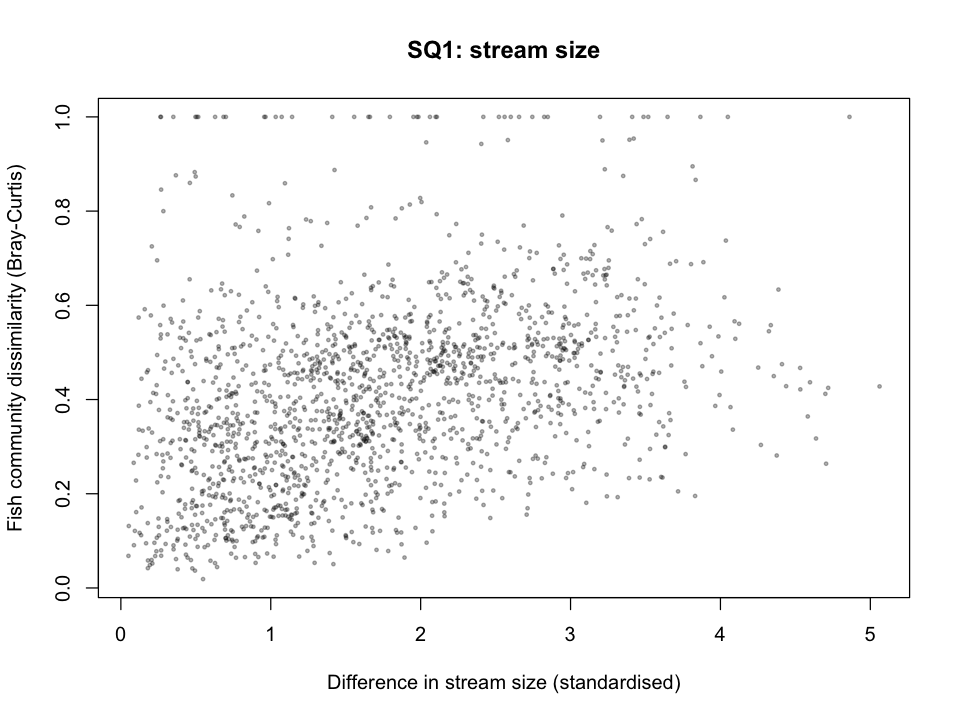

In [59]:
res_size <- mantel_row(size.d, "Stream size")
res_size

options(repr.plot.width = 8, repr.plot.height = 6)
plot(size.d, fish.d, pch = 19, cex = 0.4, col = rgb(0, 0, 0, 0.3),
     xlab = "Difference in stream size (standardised)",
     ylab = "Fish community dissimilarity (Bray-Curtis)",
     main = "SQ1: stream size")

**Result: SQ1, stream size**

| Test | Mantel r | p |
|---|---|---|
| Stream size vs composition | 0.39 | 0.001 |
| … controlling for sampling effort | 0.19 | 0.002 |
| … controlling for watershed | 0.35 | 0.001 |

- **Stream size (depth + width) significantly explains fish community composition** (Mantel r = 0.39, p = 0.001): reaches of similar size have similar fish communities.
- **Controlling for sampling effort halves the relationship** (r = 0.19), showing that part of the size effect is shared with effort (larger reaches were fished for longer). The remaining effect is still significant (p = 0.002), so stream size has an influence independent of effort.
- **Controlling for watershed changes little** (r = 0.35): the size effect is not simply a difference between Owens and Big Hunting, but also operates within watersheds.

**Scatter plot:** each point is one pair of reaches (1,770 pairs). Pairs with similar stream size mostly have low dissimilarity (≈ 0.1–0.4), while pairs differing strongly in size reach ≈ 0.4–0.6, giving an upward trend. Points at exactly 1.0 are pairs sharing no species (mostly involving FBB12, where a single brown trout was caught). The wide spread shows that size explains only part of the variation in composition.

**Hypothesis:** supported. Stream size is strongly related to composition, but, as expected, partly through sampling effort.

## SQ2 — Does substrate explain community composition?

Substrate = proportion of fine sediment (sand, silt, clay), gravel, and coarse material (cobble, boulder, bedrock) in each reach.

group,r,p,r_given_effort,p_given_effort,r_given_watershed,p_given_watershed
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Substrate,0.3223198,0.001,0.3106372,0.001,0.236175,0.001


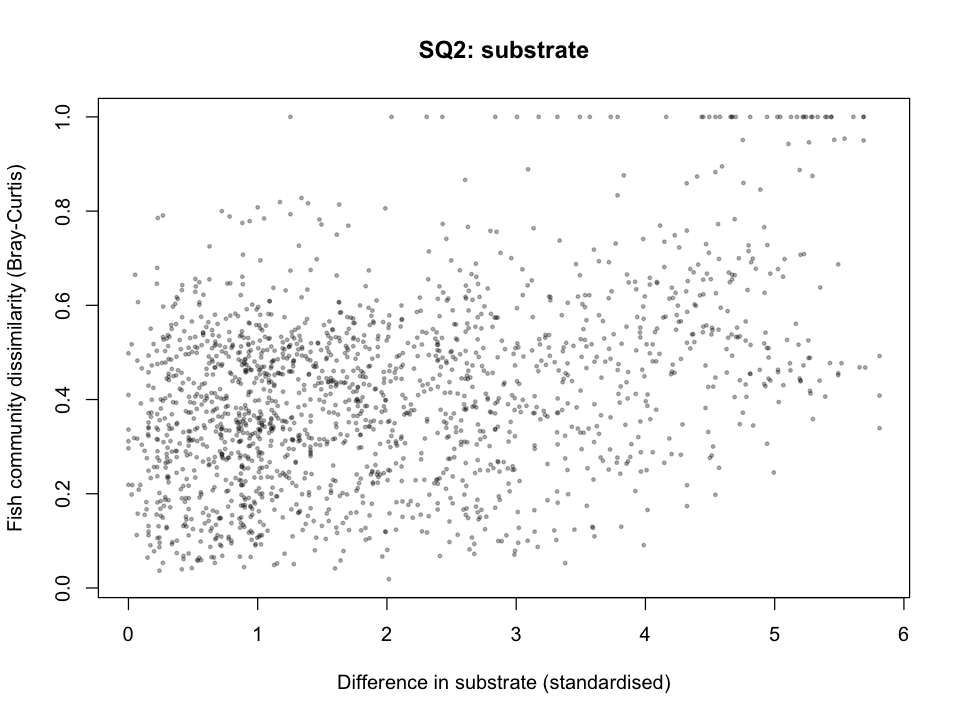

In [60]:
res_subs <- mantel_row(subs.d, "Substrate")
res_subs

plot(subs.d, fish.d, pch = 19, cex = 0.4, col = rgb(0, 0, 0, 0.3),
     xlab = "Difference in substrate (standardised)",
     ylab = "Fish community dissimilarity (Bray-Curtis)",
     main = "SQ2: substrate")

### Result: SQ2, substrate

| Test | Mantel r | p |
|---|---|---|
| Substrate vs composition | 0.32 | 0.001 |
| … controlling for sampling effort | 0.31 | 0.001 |
| … controlling for watershed | 0.24 | 0.001 |

**1. Substrate significantly explains fish community composition** (Mantel r = 0.32, p = 0.001). Reaches with a similar mix of fine sediment, gravel and coarse material have similar fish communities. On its own, this is slightly weaker than stream size (r = 0.39, SQ1).

**2. The substrate effect is almost unaffected by sampling effort** (r = 0.32 → 0.31). This is the key difference from SQ1, where controlling for effort halved the size effect (0.39 → 0.19). Substrate composition is not linked to how long a reach was fished, so its relationship with the fish community cannot be explained by sampling effort. After controlling for effort, **substrate (r = 0.31) is a stronger predictor than stream size (r = 0.19)**.

**3. Controlling for watershed reduces the effect moderately** (r = 0.32 → 0.24). Part of the substrate signal reflects differences between Owens and Big Hunting (the two watersheds differ in both substrate and fish fauna), but a clear, significant effect remains within watersheds (p = 0.001).

**Scatter plot:** each point is one pair of reaches (1,770 pairs). Pairs with similar substrate (left) mostly have dissimilarities of ≈ 0.1–0.5, while pairs with very different substrate (right) are mostly ≈ 0.4–0.7, giving an upward trend. The cluster of points at exactly 1.0 in the top right shows pairs that differ strongly in substrate and share no species at all: a few reaches with unusual substrate also have very distinct (or extremely species-poor) communities. As in SQ1, the cloud is wide, so substrate explains part, but not all, of the variation.

**Ecological interpretation:** substrate determines the space available between stones. Coarse, clean substrate (cobble, gravel) provides shelter, feeding areas and spawning sites for bottom-dwelling fish such as sculpins (COCA, COGI), darters (ETFL) and longnose dace (RHCA), and brook trout need clean gravel to spawn. Fine sediment (sand, silt) fills these gaps. This matches the species-level correlations in section 12, where these species were less abundant in reaches with more silt and sand.

**Hypothesis:** supported, and more strongly than expected. We predicted a moderate effect; substrate's effect is moderate in size but the most robust so far, as it is independent of sampling effort and only partly explained by watershed.

*Caveat:* substrate was classified visually at three points per transect, and the seven classes were grouped into three (fine, gravel, coarse); a different grouping could change the result slightly.

Substrate was significantly related to community composition (Mantel r = 0.32, p = 0.001). Although moderate in magnitude, this is about three times the value expected by chance (99th percentile of permutations = 0.11) and typical of Mantel correlations in field ecological data, where composition is influenced by many factors simultaneously.

## SQ3 — Does water temperature explain community composition?

Caveat: `Temp` is a single reading per transect, taken at whatever time the crew arrived. It is a much noisier measure than depth (averaged over ~60 points per reach), so a weak result may partly reflect measurement, not biology. The logger data would be a better temperature measure.

group,r,p,r_given_effort,p_given_effort,r_given_watershed,p_given_watershed
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Temperature,0.13055,0.005,0.1449997,0.002,-0.00796613,0.542


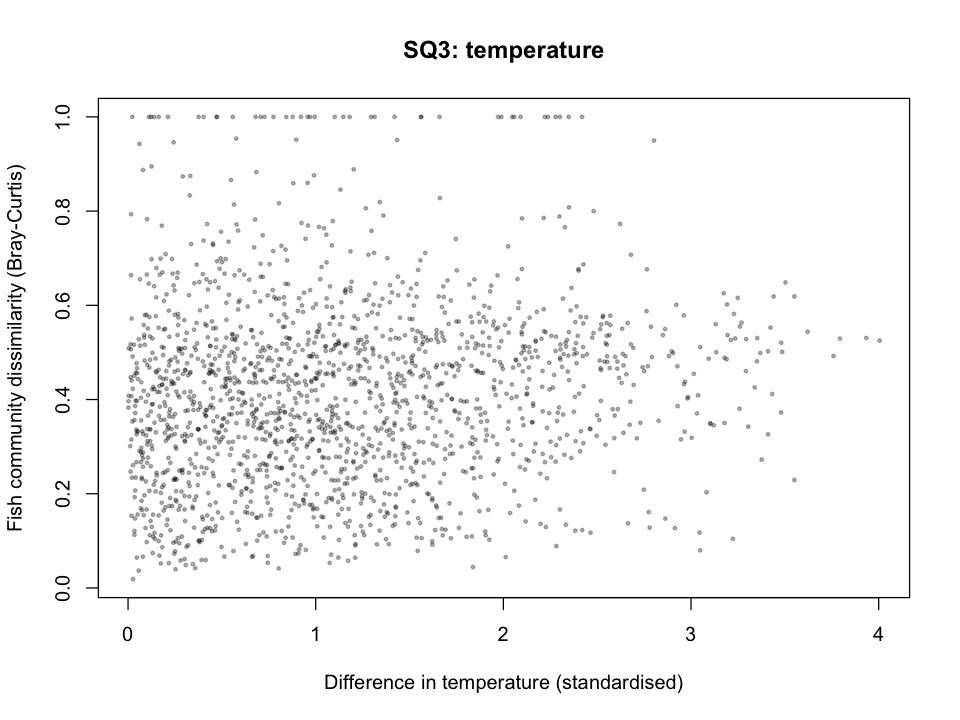

In [61]:
res_temp <- mantel_row(temp.d, "Temperature")
res_temp

plot(temp.d, fish.d, pch = 19, cex = 0.4, col = rgb(0, 0, 0, 0.3),
     xlab = "Difference in temperature (standardised)",
     ylab = "Fish community dissimilarity (Bray-Curtis)",
     main = "SQ3: temperature")

### Result: SQ3, water temperature

| Test | Mantel r | p |
|---|---|---|
| Temperature vs composition | 0.13 | 0.005 |
| … controlling for sampling effort | 0.14 | 0.002 |
| … controlling for watershed | −0.01 | 0.542 |

**1. On its own, temperature has a weak but significant relationship with community composition** (Mantel r = 0.13, p = 0.005). This is much weaker than stream size (r = 0.39) or substrate (r = 0.32), and only just above the range expected by chance.

**2. Controlling for sampling effort does not reduce it** (r = 0.14). Temperature is unrelated to how long a reach was fished; removing effort slightly sharpens the signal.

**3. Controlling for watershed makes the relationship disappear completely** (r = −0.01, p = 0.54). The whole temperature signal is explained by the difference between the two watersheds: Big Hunting reaches are warmer *and* have a different fish fauna than Owens (section 12 plot). **Within a watershed, reaches of different temperature do not have more different fish communities.** Temperature therefore acts here as a marker of watershed, not as a driver of composition.

**Scatter plot:** each point is one pair of reaches. Unlike SQ1 and SQ2, the cloud is nearly flat: pairs with very similar temperature (left) range from 0 to 1 in dissimilarity, just like pairs with very different temperature (right). There is only a faint upward tendency, consistent with the low r.

**Why temperature may appear unimportant:**
- **Measurement:** `Temp` is a single spot reading per transect, taken at whatever time of day the crew arrived and on different dates in July. It reflects sampling conditions as much as the stream's thermal regime, so it is a much noisier variable than depth or substrate (each averaged over ~60 measurements per reach).
- **Narrow range:** all reaches were between ≈ 15 and 20.5 °C. Temperature may matter mainly above a threshold (e.g. summer maxima stressful for brook trout), which spot readings in a cool range would not capture.
- **Community vs species:** temperature may affect a few cold-water species (e.g. brook trout) without changing the composition of the whole community, which is dominated by widespread species such as blacknose dace and sculpin. This is tested at species level in SQ5.

**Hypothesis:** supported. As predicted, temperature has at most a weak effect on overall community composition, and this effect is entirely explained by the difference between watersheds.

*Next step:* the logger data (hourly water temperature over summers 2015–2016) would allow a fairer test using, for example, the mean or maximum July temperature per reach.

## SQ4 — Which group explains the most, after controlling for effort and watershed?

The table puts the three groups side by side. The bar chart compares the Mantel r **after controlling for effort**, the fairest comparison.

Robustness check: the same tests with **Hellinger** distance. If the ranking of the groups is the same, the conclusion does not depend on the choice of dissimilarity.

group,r,p,r_given_effort,p_given_effort,r_given_watershed,p_given_watershed
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Stream size,0.392,0.001,0.195,0.002,0.353,0.001
Substrate,0.322,0.001,0.311,0.001,0.236,0.001
Temperature,0.131,0.005,0.145,0.002,-0.008,0.542


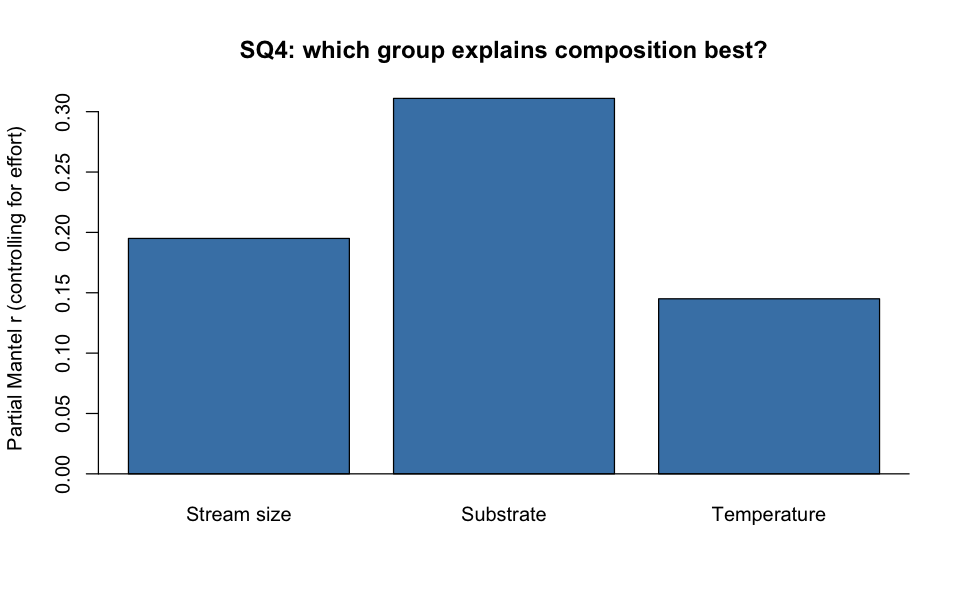

In [62]:
results <- rbind(res_size, res_subs, res_temp)
rownames(results) <- NULL
results[, -1] <- round(results[, -1], 3)
results

options(repr.plot.width = 8, repr.plot.height = 5)
barplot(results$r_given_effort, names.arg = results$group, col = "steelblue",
        ylab = "Partial Mantel r (controlling for effort)",
        main = "SQ4: which group explains composition best?")
abline(h = 0)

### How to read the Mantel results

**What a Mantel test does**
For every pair of reaches (60 reaches → 1,770 pairs) we know two things:
1. how different their **fish communities** are (Bray–Curtis dissimilarity, 0 = identical, 1 = no species in common), and
2. how different their **environment** is (e.g. difference in depth and width).

The Mantel test correlates these two lists of differences. If reaches with similar environments also have similar fish, the Mantel **r** is positive.

- **r** = strength of the relationship (0 = none, closer to 1 = stronger). Mantel r values are naturally much lower than ordinary correlations because they are computed on pairs; in ecology, r ≈ 0.1–0.3 is already meaningful.
- **p** = probability that a relationship this strong appears by chance. It is obtained by randomly shuffling the reaches 999 times and recomputing r each time. p = 0.001 means none of the 999 shuffles gave an r as high as the real one (the smallest p possible).

**What "controlling for effort" means**
*Effort* is the number of seconds the electrofisher was switched on in a reach. Fishing longer catches more fish and finds more (rarer) species. Larger reaches were also fished longer (rho = 0.79), so when large reaches show different fish, there are two possible explanations:
1. **real biology**: bigger stream → different habitat → different fish;
2. **a sampling side effect**: longer search → more species found.

A **partial Mantel test** separates the two. It removes the part of the fish differences, and the part of the environmental differences, that can be predicted from effort differences, and then correlates what is left. The result (`r_given_effort`) is the relationship as if all reaches had been fished for the same time.

*Analogy:* taller children know more words, but taller children are also older. Comparing only children of the same age ("controlling for age") shows whether height itself matters. Here effort plays the role of age.

**What "controlling for watershed" means**
The same idea, with watershed instead of effort: `r_given_watershed` asks whether the relationship also holds **within** Owens and Big Hunting, rather than just reflecting that the two creeks differ in both environment and fish.

**How to interpret the change in r**

| r after controlling… | Meaning |
|---|---|
| stays about the same | the variable has its own effect, independent of the confounder |
| drops but stays significant | part of the effect is shared with the confounder, but a real independent effect remains |
| drops to ≈ 0 (not significant) | the apparent effect was entirely due to the confounder |

**One caveat:** effort is not purely a side effect. Larger reaches naturally take longer to fish, so controlling for effort may also remove part of the *real* effect of stream size. The effort-controlled r for stream size is therefore a conservative (lower-bound) estimate.

### Result: SQ4, which group explains composition best?

| Group | Mantel r | r controlling effort | r controlling watershed |
|---|---|---|---|
| Stream size | **0.39** *** | 0.20 ** | **0.35** *** |
| Substrate | 0.32 *** | **0.31** *** | 0.24 *** |
| Temperature | 0.13 ** | 0.15 ** | −0.01 (n.s., p = 0.54) |

*** p ≤ 0.001, ** p ≤ 0.005, n.s. = not significant

**1. The ranking depends on which confounder is controlled for, and this is itself a key result.**
- **Without controls**, stream size is the strongest predictor (r = 0.39), then substrate (0.32), then temperature (0.13).
- **Controlling for sampling effort** (bar chart), **substrate becomes the strongest predictor** (r = 0.31), while stream size drops to 0.20. Stream size and effort are strongly correlated (larger reaches were fished longer), so about half of the size effect is shared with effort. Substrate is unrelated to effort and keeps almost all of its effect.
- **Controlling for watershed**, stream size remains the strongest (0.35), substrate is reduced (0.24), and temperature disappears completely (−0.01).

**2. Substrate is the most robust predictor.** It is the only group that stays strong under both controls (r = 0.31 and 0.24, both p = 0.001). Its relationship with fish composition cannot be explained by sampling effort and only partly by the difference between watersheds.

**3. Stream size is the strongest predictor overall, but its effect is partly entangled with sampling effort.** Because effort may itself be a consequence of stream size (bigger reaches take longer to fish), the effort-controlled value (0.20) is a conservative estimate; the true size effect probably lies between 0.20 and 0.39.

**4. Temperature does not independently explain composition.** Its weak signal is entirely explained by the difference between watersheds (Big Hunting is warmer and has a different fauna). Note that the bar chart, which only controls for effort, makes temperature look comparable to stream size (0.15 vs 0.20); the watershed control shows this signal is not independent.

**Answer to SQ4:** stream size and substrate both explain fish community composition independently of effort and watershed, while temperature (measured as spot readings) does not. Stream size has the largest raw effect, but substrate is the most robust once sampling effort is accounted for.

**Hypothesis:** partly supported. We expected stream size to explain the most, partly via effort. The effort part was confirmed, but after controlling for effort, substrate rather than stream size emerged as the strongest predictor.

**Limitations:**
- Each partial Mantel test controls for **one** confounder at a time (effort *or* watershed), not both together.
- Differences between r values (e.g. 0.31 vs 0.20) were not formally tested for significance.
- The three groups are not fully independent (e.g. deeper reaches may also have coarser substrate), so their effects partly overlap. Constrained ordination with variance partitioning (RDA + `varpart()`, Script 6) would separate shared and unique contributions of each group, controlling for effort and watershed simultaneously.

In [63]:
# Robustness: Hellinger distance instead of Bray-Curtis
fish.hel <- dist(decostand(spe_m, "hel"))
results_hel <- rbind(mantel_row(size.d, "Stream size", fish.hel),
                     mantel_row(subs.d, "Substrate",   fish.hel),
                     mantel_row(temp.d, "Temperature", fish.hel))
results_hel[, -1] <- round(results_hel[, -1], 3)
results_hel

group,r,p,r_given_effort,p_given_effort,r_given_watershed,p_given_watershed
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Stream size,0.265,0.001,0.162,0.006,0.205,0.001
Substrate,0.326,0.001,0.310,0.001,0.229,0.001
Temperature,0.134,0.005,0.136,0.004,-0.027,0.737


### Robustness check: Hellinger distance

The SQ1–SQ3 tests were repeated with Hellinger distance (Euclidean distance on Hellinger-transformed counts) instead of Bray–Curtis on log counts.

| Group | r | r controlling effort | r controlling watershed |
|---|---|---|---|
| Stream size | 0.27 *** | 0.16 ** | 0.21 *** |
| Substrate | **0.33** *** | **0.31** *** | **0.23** *** |
| Temperature | 0.13 ** | 0.14 ** | −0.03 (n.s., p = 0.74) |

*** p ≤ 0.001, ** p ≤ 0.006, n.s. = not significant

**Robust conclusions** (same with both distances):
- Stream size and substrate are both significantly related to community composition, independently of effort and watershed.
- Substrate is almost unaffected by any control (r ≈ 0.31–0.33, or 0.23 within watersheds).
- Temperature has only a weak effect, which disappears entirely once watershed is controlled.

**What differs:** stream size is weaker with Hellinger (r = 0.27 instead of 0.39), so **substrate becomes the strongest predictor in all three tests**. The two distances answer slightly different questions. Bray–Curtis on log counts is sensitive to differences in total abundance (how many fish), while Hellinger is based on relative proportions (which species dominate the catch). Larger reaches mainly hold *more* fish, which affects Bray–Curtis but not Hellinger.

**Interpretation:** stream size is associated partly with the **abundance** of fish, whereas substrate is associated with the **relative make-up** of the community (which species dominate). Combined with SQ4, substrate emerges as the most consistent predictor of fish community composition across both dissimilarity measures and all controls; the importance of stream size depends on whether total abundance is considered part of "composition".

## SQ5 — Is brook trout abundance related to temperature?

Brook trout (SAFO) are the species the study was designed around: native, and dependent on cold water.
- Spearman correlation overall and **within each watershed** (to avoid the watershed effect seen with brown trout).
- A linear model on log counts that includes effort and watershed, so the temperature coefficient is the effect *at equal effort and within the same watershed*.


	Spearman's rank correlation rho

data:  d5$safo and d5$Temp
S = 53222, p-value = 0.0001089
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.4788021 


d5$ws: Big Hunting

	Spearman's rank correlation rho

data:  d$safo and d$Temp
S = 802.34, p-value = 0.9491
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
0.01674248 

------------------------------------------------------------ 
d5$ws: Owens

	Spearman's rank correlation rho

data:  d$safo and d$Temp
S = 16159, p-value = 0.1562
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.2200624 



Call:
lm(formula = safo ~ Temp + eff + ws, data = d5)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.98360 -0.60326  0.04342  0.43301  2.40921 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  5.8039856  2.2356670   2.596  0.01202 *  
Temp        -0.3549020  0.1170979  -3.031  0.00369 ** 
eff          0.0015100  0.0002016   7.491 5.34e-10 ***
wsOwens      0.6428622  0.3513886   1.829  0.07265 .  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.878 on 56 degrees of freedom
Multiple R-squared:  0.6666,	Adjusted R-squared:  0.6488 
F-statistic: 37.33 on 3 and 56 DF,  p-value: 2.185e-13


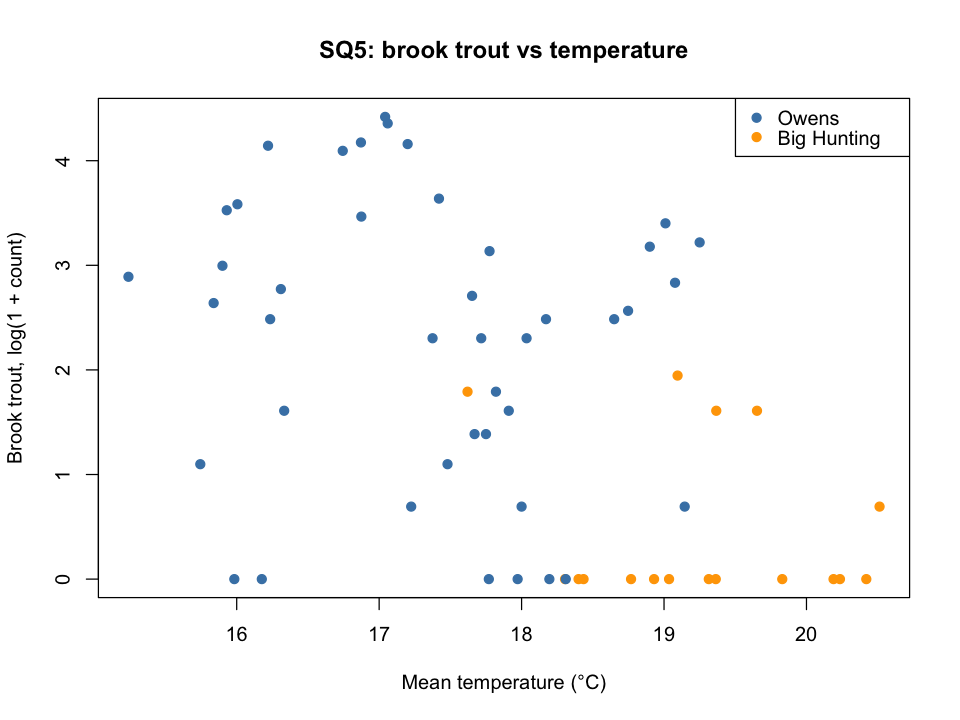

In [64]:
safo <- log1p(spe$SAFO)
d5 <- data.frame(safo, Temp = env_reach$Temp, eff, ws)
d5 <- d5[complete.cases(d5), ]

# Overall and within each watershed
cor.test(d5$safo, d5$Temp, method = "spearman", exact = FALSE)
by(d5, d5$ws, function(d) cor.test(d$safo, d$Temp, method = "spearman", exact = FALSE))

# Model: temperature effect at equal effort and within watershed
mod_safo <- lm(safo ~ Temp + eff + ws, data = d5)
summary(mod_safo)

options(repr.plot.width = 8, repr.plot.height = 6)
plot(d5$Temp, d5$safo, pch = 19,
     col = ifelse(d5$ws == "Owens", "steelblue", "orange"),
     xlab = "Mean temperature (°C)", ylab = "Brook trout, log(1 + count)",
     main = "SQ5: brook trout vs temperature")
legend("topright", legend = c("Owens", "Big Hunting"),
       col = c("steelblue", "orange"), pch = 19)

### Result: SQ5, brook trout and temperature

**Correlations (Spearman, log1p brook trout counts vs mean temperature):**

| Data | rho | p |
|---|---|---|
| All reaches | −0.48 | 0.0001 |
| Big Hunting only | 0.02 | 0.95 |
| Owens only | −0.22 | 0.16 |

**Linear model:** `log1p(SAFO) ~ Temp + effort + watershed` (n = 60 reaches)

| Term | Estimate | p | Interpretation |
|---|---|---|---|
| Temperature | −0.355 | 0.004 | ≈ 30% fewer brook trout per +1 °C (e^−0.355 ≈ 0.70) |
| Effort | 0.0015 | < 0.001 | ≈ 2.5× more brook trout per extra 10 min of electrofishing |
| Watershed (Owens) | 0.64 | 0.07 | Owens tends to have more brook trout (marginal) |

R² = 0.67 (adjusted 0.65), F = 37.3, p < 0.001.

**Interpretation**

1. **Brook trout are less abundant in warmer reaches.** Across all reaches the negative correlation is moderate and highly significant (rho = −0.48). Part of this reflects the watershed difference: Big Hunting reaches are warmer and hold few brook trout.

2. **The temperature effect persists after controlling for effort and watershed.** In the linear model, each additional °C is associated with roughly 30% fewer brook trout (p = 0.004), comparing reaches with the same sampling effort within the same watershed. Effort is the strongest predictor (more fishing catches more trout), and Owens tends to support more brook trout than Big Hunting.

3. **Within-watershed correlations are weaker.** In Owens, the correlation has the same negative direction (rho = −0.22) but is not significant on its own, partly because it ignores sampling effort, which adds considerable noise to the counts, and uses fewer reaches. In Big Hunting the test is not informative: brook trout were absent from all 12 FBB reaches and present only in the 6 FBM reaches, leaving little variation to analyse.

4. **Contrast with SQ3:** temperature did not explain the composition of the *whole* fish community once watershed was controlled, but it does explain the abundance of the cold-water specialist brook trout. The community is dominated by widespread, temperature-tolerant species (blacknose dace, sculpin), so a temperature effect on one sensitive species does not show up in community-level distances.

**Hypothesis:** supported. Brook trout abundance decreases with water temperature, independently of sampling effort and watershed, consistent with the study's motivation (cold-water habitat for native brook trout under climate change).

**Caveats**
- Temperature is a single spot reading per transect; the logger data (summer mean or maximum) would be a more reliable measure.
- The model is fitted on log(1 + count); percentage effects are approximate, and many reaches have zero trout.
- The absence of brook trout from all FBB reaches, where brown trout (SATR) are most common, may reflect competition with brown trout or other factors (e.g. barriers, stocking history), not temperature alone.
- Observational data: the results show association, not causation. Model diagnostics (`plot(mod_safo)`) should be checked as in section 13.

## Summary

**Research question:** To what extent do stream size, substrate and water temperature explain differences in fish community composition among stream reaches in Catoctin Mountain Park, once sampling effort and watershed are accounted for?

| Sub-question | Result (Bray–Curtis; Hellinger in brackets) | Hypothesis supported? |
|---|---|---|
| **SQ1 Stream size** | Mantel r = 0.39 (0.27), p = 0.001; controlling effort r = 0.20 (0.16), p = 0.002; controlling watershed r = 0.35 (0.21), p = 0.001 | **Yes**: significant independent effect, but about half of it is shared with sampling effort |
| **SQ2 Substrate** | Mantel r = 0.32 (0.33), p = 0.001; controlling effort r = 0.31 (0.31), p = 0.001; controlling watershed r = 0.24 (0.23), p = 0.001 | **Yes, more strongly than expected**: moderate but the most robust effect, unaffected by effort |
| **SQ3 Temperature** | Mantel r = 0.13 (0.13), p = 0.005; controlling effort r = 0.15 (0.14), p = 0.002; controlling watershed r = −0.01 (−0.03), p = 0.54 (0.74) | **Yes**: weak effect on the whole community, entirely explained by the watershed difference |
| **SQ4 Ranking** | No controls: size > substrate > temperature. Controlling effort: substrate > size > temperature. With Hellinger: substrate strongest in all tests | **Partly**: size explains most before controls, but substrate is the strongest predictor once effort is accounted for, and the most consistent overall |
| **SQ5 Brook trout** | Overall rho = −0.48, p = 0.0001; within Owens rho = −0.22 (n.s.); model Temp coefficient = −0.355 (≈ 30% fewer trout per +1 °C), p = 0.004, controlling effort and watershed; R² = 0.67 | **Yes**: brook trout decrease with temperature independently of effort and watershed |

### Answer to the research question

Fish community composition in Catoctin Mountain Park is explained mainly by **physical habitat**: both **stream size** and **substrate** have significant effects that remain after controlling for sampling effort and watershed. **Substrate** is the most robust predictor: its effect is unchanged by sampling effort and consistent across both dissimilarity measures. **Stream size** has the largest raw effect, but part of it is shared with sampling effort (larger reaches were fished longer) and with total fish abundance. **Water temperature**, measured as spot readings, does not explain the composition of the whole community once the difference between watersheds is accounted for, but it **does** explain the abundance of the cold-water specialist **brook trout**, which declines in warmer reaches. This matches the study's focus on brook trout and climate change.

### Limitations

- **Observational data:** results show associations, not causes.
- **Single summer survey** (July 2015): communities and habitat may differ between years and seasons.
- **Temperature from single spot readings**, taken at different times of day and on different dates; the logger data would give a more reliable thermal measure.
- **Effort and stream size are strongly correlated** (rho = 0.79), so their effects are hard to separate; the effort-controlled size effect is a conservative estimate.
- **Neighbouring reaches along the same creek are not fully independent** (spatial autocorrelation), which can inflate significance.
- **Partial Mantel tests control for one confounder at a time**, and differences between r values were not formally tested.
- **Rare species** (AMNA, MISA, LEMA) and **4 reaches with missing habitat data** were excluded.
- Substrate classes were grouped into three categories (fine, gravel, coarse); other groupings could change results slightly.

### Next steps

- Use **logger temperatures** (e.g. summer mean or maximum per reach) to test temperature more fairly.
- Apply **constrained ordination (RDA) with variance partitioning** (Script 6) to estimate the unique and shared contributions of size, substrate and temperature, controlling for effort and watershed simultaneously.
- Investigate the **absence of brook trout from the FBB reaches**, where brown trout are most common (possible competition or barriers).

ggplot2
ggpubr - do boxplots for the variance and everything
in charge of environment analysis + other fish species

https://r-graph-gallery.com
